In [4]:
import pandas as pd
import seaborn as sbn
import numpy as np
import ast
from shapely.geometry import Polygon, Point
import matplotlib.pyplot as plt

# Mandatory 2 – Predikere om et skudd blir mål (StatsBomb, Barcelona i Messi-årene)

## 1. Mål med notebooken
Målet er å bygge en klassifikasjonsmodell som, ut fra informasjon om selve skuddsituasjonen, predikerer om et skudd ender i **mål** eller **ikke mål**. Datasettet består av **alle skudd i La Liga-kamper der Barcelona deltok** i Messi-årene i tillegg til **en** helt stråelende kamp fra 1973/1974 sesogen hvor **legenden Johan Cruyff** skåret og vant **5-0** over real mardird i deres hjemme bane, både Barcelonas egne skudd og motstandernes. Hvilket lag som skyter er med som en feature (`team`).

Målvariabelen lages fra kolonnen `shot_outcome`:
- `1` = `Goal`
- `0` = alle andre utfall (redda, utenfor mål, i stolpen, blokkert osv.)

Features er det som er kjent *i øyeblikket skuddet tas*: posisjon på banen, avstand og vinkel mot mål, kroppsdel, teknikk, spillsituasjon (`play_pattern`, `shot_type`), press, og hvordan keeper og forsvarere står plassert (`shot_freeze_frame`). Informasjon som først er kjent *etter* skuddet (f.eks. hvor ballen endte, `shot_end_location`) brukes ikke som feature fordi det er datalekkasje.

## 2. Data
**Kilde:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (åpent og gratis tilgjengelig event-data fra fotballkamper). Data er kreditert StatsBomb.

**Hvordan datasettet ble laget:**
1. Hentet oversikten over alle konkurranser og filtrerte på La Liga (18 sesonger).
2. Hentet alle kampene i La Liga og beholdt de der Barcelona spilte hjemme eller borte (525 kamper). Dette dekker sesongene 2004/05–2020/21, de årene Messi spilte for klubben, pluss én kamp fra 1973/74 (Real Madrid–Barcelona 0–5, Cruyff-tiden). Den kampen ble beholdt bevisst, siden den utgjør en svært liten del av datasettet og påvirker ikke resultatene.
3. Hentet alle hendelser (events) fra de 525 kampene og beholdt alle hendelser av typen `Shot`, uavhengig av hvilket lag som skjøt (Barcelona: 8 285 skudd, motstanderne: 4 700).
4. Valgte ut 24 relevante kolonner av de opprinnelige 119 (resten var tomme for skudd eller ikke relevante) og lagret resultatet som `barca_shots_events.csv`.

Datainnhentingen og filtreringen ble gjort over flere iterasjoner i et eget skript (`StatsBombEventsBarcelona`) og er ikke en del av denne innleveringen. Notebooken starter med den ferdige CSV-filen, slik at den kan kjøres uten nettverkstilgang.

**Størrelse:** 12 985 skudd, hvorav 1 775 mål (ca. 13,7 %).

## 3. Utfordring: ubalanserte klasser
Bare omtrent **1 av 7 skudd** blir mål. En modell som alltid svarer «ikke mål» får rundt 86 % *accuracy* uten å lære noe, så accuracy alene er misvisende her. Derfor legger jeg vekt på:
- precision, recall og F1 for målklassen, samt confusion matrix og precision-recall-kurver
- stratifisert deling og håndtering av ubalansen (f.eks. `class_weight`)
- `GroupKFold` på `match_id`, slik at skudd fra samme kamp ikke havner både i trening og test

## 4. Hva jeg vil lære av oppgaven
Oppgaven er også en mulighet til å jobbe grundig med metodene fra kurset:
- **Databehandling:** rensing, feature engineering (avstand, vinkel, freeze-frame-features), skalering, *power transformations* og *Principal Component Analysis (PCA)*
- **Pipelines** med `Pipeline` og `ColumnTransformer`, slik at all behandling skjer innenfor krysspvalideringen uten lekkasje
- **Automatisk hyperparameter-tuning** (og tuning av behandlingsvalg) og **kryssvalidering**
- **Modeller:** to baseline-modeller, tre avanserte modeller (bl.a. *bagging* og *boosting*) og til slutt et **kunstig nevralt nettverk (ANN)**
- **Evaluering** og sammenligning av alle modellene, også mot StatsBombs egen xG-modell (`shot_statsbomb_xg`) som ekstern referanse

## 5. Oversikt over notebooken
1. Innlasting og første inspeksjon
2. Databehandling og feature engineering
3. Utforskende dataanalyse (EDA) 
4. Baseline-modeller
5. Avanserte modeller og tuning
6. ANN
7. Evaluering og sammenligning
8. Konklusjon og begrensninger

In [5]:
barcelona_shots = pd.read_csv("data\\barcelona_shots_events.csv")

In [6]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [7]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,NaN,NaN,Right Foot,NaN,"[120.0, 47.8, 0.0]",NaN,"[{'location': [91.6, 30.4], 'player': {'id': 5...",True,NaN,0.200969,Normal,Open Play,Off T
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,NaN,NaN,Right Foot,NaN,"[115.8, 42.1, 0.0]",True,"[{'location': [97.2, 35.3], 'player': {'id': 2...",NaN,NaN,0.096384,Normal,Open Play,Saved
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,NaN,NaN,Left Foot,NaN,"[120.0, 50.6, 0.0]",True,"[{'location': [104.3, 36.7], 'player': {'id': ...",NaN,NaN,0.098879,Normal,Open Play,Off T
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,NaN,NaN,Left Foot,NaN,"[119.8, 37.6]",NaN,"[{'location': [114.1, 43.8], 'player': {'id': ...",NaN,NaN,0.078938,Normal,Free Kick,Blocked
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,NaN,NaN,Left Foot,NaN,"[120.0, 40.7, 0.0]",NaN,"[{'location': [108.6, 55.2], 'player': {'id': ...",True,True,0.976192,Normal,Open Play,Goal


In [8]:
barcelona_shots[barcelona_shots["player"] == "Johan Cruyff"]

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome
12967,3888713,Barcelona,Johan Cruyff,39713.0,34,57,1,Center Forward,"[108.0, 43.2]",0.872205,Regular Play,NaN,NaN,Left Foot,NaN,"[120.0, 40.5, 0.0]",NaN,"[{'location': [109.7, 38.6], 'player': {'id': ...",NaN,NaN,0.578706,Normal,Open Play,Goal
12973,3888713,Barcelona,Johan Cruyff,39713.0,52,33,2,Center Forward,"[98.3, 30.9]",1.391505,From Counter,NaN,NaN,Right Foot,NaN,"[120.0, 45.2, 6.7]",NaN,"[{'location': [97.6, 29.0], 'player': {'id': 3...",NaN,NaN,0.053107,Normal,Open Play,Off T
12975,3888713,Barcelona,Johan Cruyff,39713.0,57,14,2,Center Forward,"[98.3, 23.8]",2.020851,From Throw In,NaN,NaN,Right Foot,NaN,"[120.0, 52.9, 0.0]",NaN,"[{'location': [95.2, 40.2], 'player': {'id': 3...",NaN,NaN,0.021481,Half Volley,Open Play,Off T
12976,3888713,Barcelona,Johan Cruyff,39713.0,57,38,2,Center Forward,"[98.2, 42.2]",0.277758,Regular Play,NaN,NaN,Right Foot,NaN,"[101.7, 42.6]",NaN,"[{'location': [118.7, 40.6], 'player': {'id': ...",NaN,NaN,0.074925,Normal,Open Play,Blocked
12984,3888713,Barcelona,Johan Cruyff,39713.0,86,34,2,Center Forward,"[100.2, 49.9]",0.202476,From Throw In,NaN,NaN,Right Foot,NaN,"[103.1, 47.9]",NaN,"[{'location': [88.5, 63.6], 'player': {'id': 3...",NaN,NaN,0.044297,Half Volley,Open Play,Blocked


In [9]:
barcelona_shots.dtypes

match_id                  int64
team                        str
player                      str
player_id               float64
minute                    int64
second                    int64
period                    int64
position                    str
location                    str
duration                float64
play_pattern                str
under_pressure           object
shot_follows_dribble     object
shot_body_part              str
shot_aerial_won          object
shot_end_location           str
shot_first_time          object
shot_freeze_frame           str
shot_one_on_one          object
shot_open_goal           object
shot_statsbomb_xg       float64
shot_technique              str
shot_type                   str
shot_outcome                str
dtype: object

### Datatyper
Her ser jeg hvilken datatype hver kolonne har.

- **Tall** (`int64`/`float64`): `match_id`, `minute`, `second`, `period`, `duration`, `shot_statsbomb_xg` og `player_id`. `player_id` er `float64` selv om det er et heltall, så den gjør jeg om til `int` senere.
- **Tekst** (`str`): `team`, `player`, `position`, `play_pattern`, `shot_body_part`, `shot_technique`, `shot_type` og `shot_outcome`. Tekstkategoriene må encodes til tall før modellene kan bruke dem.
- **Lister som tekst:** `location`, `shot_end_location` og `shot_freeze_frame` vises som `str` fordi dataene ligger i en CSV-fil. Listene ble til tekststrenger da filen ble lagret, og må gjøres om til ekte lister igjen.
- **`object`:** de seks flaggkolonnene (`under_pressure`, `shot_follows_dribble`, `shot_aerial_won`, `shot_first_time`, `shot_one_on_one`, `shot_open_goal`) er `object` fordi de blander `True` og tomme verdier. De må ryddes opp.

In [10]:
barcelona_shots.isna().mean()

match_id                0.000000
team                    0.000000
player                  0.000000
player_id               0.000000
minute                  0.000000
second                  0.000000
period                  0.000000
position                0.000000
location                0.000000
duration                0.000000
play_pattern            0.000000
under_pressure          0.837659
shot_follows_dribble    0.998999
shot_body_part          0.000000
shot_aerial_won         0.941625
shot_end_location       0.000000
shot_first_time         0.692337
shot_freeze_frame       0.010705
shot_one_on_one         0.928071
shot_open_goal          0.987062
shot_statsbomb_xg       0.000000
shot_technique          0.000000
shot_type               0.000000
shot_outcome            0.000000
dtype: float64

### Manglende verdier
Her ser jeg andelen manglende verdier (0 = ingen mangler, 1 = alt mangler) i hver kolonne.

- **De fleste kolonnene er komplette** (0,0).
- **Flaggkolonnene har mange tomme verdier**: `shot_follows_dribble` (99,9 %), `shot_open_goal` (98,7 %), `shot_aerial_won` (94,2 %), `shot_one_on_one` (92,8 %), `under_pressure` (83,8 %) og `shot_first_time` (69,2 %). Dette er ikke ekte manglende data. StatsBomb fyller bare inn `True` når noe skjedde, så tom betyr «nei».
- **`shot_freeze_frame` mangler for 1,1 % av skuddene.** Det er de 139 straffesparkene, som ikke har noen freeze frame.

In [11]:
#Location 
# [ <gjør_noe_med_elementet> for element in <samling_av_elementer> if <betingelse> ]
#barcelona_shots["location"] = barcelona_shots["location"].apply(ast.literal_eval)

In [12]:
barcelona_shots["location"].isna().sum()

np.int64(0)

In [13]:
def converting_columns_to_list(column_name):
    barcelona_shots[column_name] = [ast.literal_eval(rad) if isinstance(rad, str)  
    else rad if isinstance(rad, list)
    else []
    for rad in barcelona_shots[column_name] ]

In [14]:
converting_columns_to_list("location")
converting_columns_to_list("shot_end_location")
converting_columns_to_list("shot_freeze_frame")

In [15]:
barcelona_shots.isna().mean()

match_id                0.000000
team                    0.000000
player                  0.000000
player_id               0.000000
minute                  0.000000
second                  0.000000
period                  0.000000
position                0.000000
location                0.000000
duration                0.000000
play_pattern            0.000000
under_pressure          0.837659
shot_follows_dribble    0.998999
shot_body_part          0.000000
shot_aerial_won         0.941625
shot_end_location       0.000000
shot_first_time         0.692337
shot_freeze_frame       0.000000
shot_one_on_one         0.928071
shot_open_goal          0.987062
shot_statsbomb_xg       0.000000
shot_technique          0.000000
shot_type               0.000000
shot_outcome            0.000000
dtype: float64

### Lister og manglende verdier i `location`-kolonnene
Kolonnene `location`, `shot_end_location` og `shot_freeze_frame` var lister som hadde blitt til tekst da dataene ble lagret som CSV. Jeg har derfor skrevet funksjonen `converting_columns_to_list`, som gjør teksten om til lister igjen. Funksjonen kan kjøres flere ganger uten å ødelegge dataene, og de 139 manglende freeze frames (straffer) blir til tomme lister `[]`.

Etter konverteringen mangler ingen verdier i disse tre kolonnene. Det betyr ikke at straffene har fått en freeze frame, men at den er en tom liste. Det tar jeg hensyn til når jeg lager features fra den senere.

In [16]:
flag_cols= ["under_pressure", "shot_follows_dribble", "shot_aerial_won", 
                 "shot_first_time", "shot_one_on_one", "shot_open_goal"]

In [17]:
barcelona_shots[flag_cols] = barcelona_shots[flag_cols].fillna(value=False)
barcelona_shots[flag_cols] = barcelona_shots[flag_cols].astype(int)

In [18]:
barcelona_shots[flag_cols].dtypes

under_pressure          int64
shot_follows_dribble    int64
shot_aerial_won         int64
shot_first_time         int64
shot_one_on_one         int64
shot_open_goal          int64
dtype: object

In [19]:
barcelona_shots[flag_cols].sum()

under_pressure          2108
shot_follows_dribble      13
shot_aerial_won          758
shot_first_time         3995
shot_one_on_one          934
shot_open_goal           168
dtype: int64

### Flaggkolonnene til 0 og 1
De seks flaggkolonnene (`under_pressure`, `shot_follows_dribble`, `shot_aerial_won`, `shot_first_time`, `shot_one_on_one`, `shot_open_goal`) hadde bare `True` eller tomt, der tomt betyr «nei». Jeg fylte de tomme verdiene med `False` og gjorde `True`/`False` om til `1`/`0`. Dette er en enkel form for koding (encoding).

Etter konverteringen er alle seks kolonnene `int64`, og summene stemmer med antallet `True` før konverteringen: 2 108 skudd under press, 3 995 første-berøringsskudd, 934 en-mot-en, 758 hodeduellseire, 168 mot åpent mål og 13 etter dribling.

Flaggene er sjeldne, så de fleste verdiene er 0. `shot_follows_dribble` har bare 13 enere og vil sannsynligvis ikke bety mye for modellen.

In [20]:
barcelona_shots["location_x"] = barcelona_shots["location"].str[0]
barcelona_shots["location_y"] = barcelona_shots["location"].str[1]

In [21]:
#np.sqrt((120 - df['x'])**2 + (40 - df['y'])**2)
barcelona_shots["shot_distance_from_goal"] = np.sqrt((120- barcelona_shots["location_x"])**2 + (40 - barcelona_shots["location_y"])**2 )

In [22]:
barcelona_shots.head()
#scale_pos_weight i XGBoost eller bruke class_weight='balanced'

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851


In [23]:
#df['vinkel_senter'] = np.degrees(np.arctan2(np.abs(40 - df['y']), 120 - df['x']))
barcelona_shots["shot_angle"] = np.degrees(np.arctan2(np.abs(40- barcelona_shots["location_y"]), 120 - barcelona_shots["location_x"]))

In [24]:
teller = 8 * (120 - barcelona_shots['location_x'])
nevner = (120 - barcelona_shots['location_x'])**2 + (36 - barcelona_shots['location_y']) * (44 - barcelona_shots['location_y'])

barcelona_shots['shot_angle_visual'] = np.degrees(np.arctan2(teller, nevner))

In [25]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287


### Posisjonsfeatures: avstand og to vinkler
Posisjonen er gitt som `x` (banens lengde, 0–120) og `y` (bredden, 0–80). Begge lag angriper mot x = 120, målmidten ligger på (120, 40), og stolpene står på y = 36 og y = 44. Fra `x` og `y` har jeg laget tre features:

- **`shot_distance_from_goal`**: faktisk avstand til målmidten, regnet ut med Pythagoras: √((120 − x)² + (40 − y)²). Kort avstand gir normalt større sjanse for mål.
- **`shoot_angle`**: vinkelen bort fra midtlinjen mot mål, regnet ut med `arctan2`. 0° betyr rett foran mål, og 90° betyr helt ute ved dødlinjen. Den sier hvor skeivt skuddet er tatt, men ikke hvor stort mål skytteren har å sikte på.
- **`shot_angle_visual`**: åpningsvinkelen, altså vinkelen mellom linjene fra skytteren til de to stolpene. Den sier hvor stor del av målet skytteren ser. Formelen er hentet fra [Soccermatics, «The geometry of shooting»](https://soccermatics.readthedocs.io/en/latest/lesson2/GeometryOfShooting.html) (David Sumpter) og tilpasset StatsBombs koordinater, der målet er 8 enheter bredt: `8·dx / (dx² + (36 − y)(44 − y))`, med `dx = 120 − x`. 

**Forskjellen på de to vinklene:** Et skudd rett foran mål, men langt ute, har `shoot_angle` = 0°, men en liten åpning (ca. 15°). Et skudd fra siden i boksen har stor `shoot_angle` (46°), men en åpning på ca. 19°. Helt ute ved dødlinjen er `shoot_angle` nesten 90°, men åpningen bare noen få grader. Åpningsvinkelen er en ikke-lineær kombinasjon av posisjonen som enkle modeller (som logistisk regresjon) vanskelig kan lære selv. Jeg har derfor laget den på forhånd og vil sammenligne hvor mye hver av dem betyr for modellene senere.

In [26]:
barcelona_shots.dtypes

match_id                     int64
team                           str
player                         str
player_id                  float64
minute                       int64
second                       int64
period                       int64
position                       str
location                    object
duration                   float64
play_pattern                   str
under_pressure               int64
shot_follows_dribble         int64
shot_body_part                 str
shot_aerial_won              int64
shot_end_location           object
shot_first_time              int64
shot_freeze_frame           object
shot_one_on_one              int64
shot_open_goal               int64
shot_statsbomb_xg          float64
shot_technique                 str
shot_type                      str
shot_outcome                   str
location_x                 float64
location_y                 float64
shot_distance_from_goal    float64
shot_angle                 float64
shot_angle_visual   

In [27]:
barcelona_shots["shot_freeze_frame"][0]

[{'location': [91.6, 30.4],
  'player': {'id': 5487, 'name': 'Antoine Griezmann'},
  'position': {'id': 23, 'name': 'Center Forward'},
  'teammate': True},
 {'location': [99.2, 43.8],
  'player': {'id': 5503, 'name': 'Lionel Andrés Messi Cuccittini'},
  'position': {'id': 19, 'name': 'Center Attacking Midfield'},
  'teammate': True},
 {'location': [96.7, 53.3],
  'player': {'id': 6612, 'name': 'Rubén Duarte Sánchez'},
  'position': {'id': 6, 'name': 'Left Back'},
  'teammate': False},
 {'location': [95.7, 33.4],
  'player': {'id': 6615, 'name': 'Víctor Laguardia Cisneros'},
  'position': {'id': 3, 'name': 'Right Center Back'},
  'teammate': False},
 {'location': [103.8, 40.0],
  'player': {'id': 3093, 'name': 'Florian Grégoire Claude Lejeune'},
  'position': {'id': 5, 'name': 'Left Center Back'},
  'teammate': False},
 {'location': [106.0, 29.2],
  'player': {'id': 6923, 'name': 'Joaquín Navarro Jiménez'},
  'position': {'id': 2, 'name': 'Right Back'},
  'teammate': False},
 {'location

In [28]:
barcelona_shots["keeper_x"] =barcelona_shots["shot_freeze_frame"].apply(lambda x: 
                                           [spiller.get("location") for spiller in x if isinstance(spiller, dict) and spiller.get("position")["name"] == "Goalkeeper" and spiller.get("teammate") == False][0][0] 
                                           if isinstance(x, list) and len([s for s in x if isinstance(s, dict) and s.get("position")["name"] == "Goalkeeper" and s.get("teammate") == False]) > 0 else None) 

In [29]:
barcelona_shots["keeper_y"] = barcelona_shots["shot_freeze_frame"].apply(lambda x: 
                                           [spiller.get("location") for spiller in x if isinstance(spiller, dict) and spiller.get("position")["name"] == "Goalkeeper" and spiller.get("teammate") == False ][0][1]
                                           if isinstance(x, list) and len([s for s in x if isinstance(s, dict) and s.get("position")["name"] == "Goalkeeper" and s.get("teammate") == False]) > 0 else None) 

In [30]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3


In [31]:
def pythagoras(x1, y1, x2, y2):
   return np.sqrt(((x2-x1)**2) + ((y2-y1)**2))

In [32]:
def distance_column_maker(dataset, columnx1, columny1,  columnx2,columny2, newcolumn):
   dataset[newcolumn] = pythagoras(dataset[columnx1], dataset[columny1], dataset[columnx2], dataset[columny2])
      

In [33]:
distance_column_maker(barcelona_shots, columnx1="location_x", columny1="location_y", columnx2="keeper_x", columny2="keeper_y", newcolumn="distance_between_shooter_and_keeper")

In [34]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987


In [35]:
barcelona_shots.isna().sum()

match_id                                 0
team                                     0
player                                   0
player_id                                0
minute                                   0
second                                   0
period                                   0
position                                 0
location                                 0
duration                                 0
play_pattern                             0
under_pressure                           0
shot_follows_dribble                     0
shot_body_part                           0
shot_aerial_won                          0
shot_end_location                        0
shot_first_time                          0
shot_freeze_frame                        0
shot_one_on_one                          0
shot_open_goal                           0
shot_statsbomb_xg                        0
shot_technique                           0
shot_type                                0
shot_outcom

In [36]:
barcelona_shots.loc[148, ["keeper_x", "keeper_y"]]

keeper_x    117.5
keeper_y     40.7
Name: 148, dtype: float64

### Features fra `shot_freeze_frame`
Kolonnen `shot_freeze_frame` er spesiell fordi den gir et «frossent bilde» av banen i det øyeblikket skuddet ble tatt. For hvert skudd får vi en liste over spillerne som var synlige, med posisjon, rolle (f.eks. keeper eller back) og om de er medspiller eller motstander. Listen er ikke et tall, så modellene kan ikke bruke den direkte. Jeg gjør den derfor om til features med fast betydning.

I feature engineering er målet å gi modellen så mye relevant informasjon om hendelsen som mulig. Jeg mener at gode features ofte er minst like viktig som tuning av selve modellen. Jeg har derfor valgt fire features fra frysebildet:

1. **Avstand mellom skytteren og keeperen**
2. **Avstand mellom keeperen og målmidten**
3. **Antall motstandere rundt skytteren**, talt i tre ringer med ulik radius (hvor kompakt forsvaret står)
4. **Antall motstandere i trekanten** mellom skytteren og de to stolpene (altså de som står i skuddlinjen)

Jeg lager ikke én kolonne per spiller. Antall spillere varierer fra skudd til skudd, og rekkefølgen i listen er tilfeldig, så slike kolonner ville vært nesten tomme og uten fast betydning.

#### Feature 1: avstand mellom skytteren og keeperen
Jeg gjorde dette i tre steg:
1. **Fant keeperen i hver rad.** Jeg gikk gjennom spillerne i frysebildet og valgte den som har posisjonen `Goalkeeper` og som *ikke* er medspiller. Sjekken på medspiller er viktig, for i noen skudd er egen keeper også synlig i bildet, og da ville jeg fått feil keeper.
2. **Hentet ut keeperens `x` og `y`** i to nye kolonner, `keeper_x` og `keeper_y`.
3. **Regnet ut avstanden** mellom skytteren og keeperen med Pythagoras' setning og la den i kolonnen `distance_between_shooter_and_keeper`.

Jeg kontrollerte at resultatet stemmer ved å regne for hånd på første skudd (skytter på (108,6, 28,0), keeper på (114,5, 33,8) gir ca. 8,27) og ved å teste på en rad der egen keeper står først i lista.

**Manglende verdier:** 151 skudd har ingen keeper. 139 er straffespark, som ikke har noe frysebilde, og 12 er skudd der motstanderens keeper ikke var synlig. Disse får `NaN` i alle keeperkolonnene. Det håndterer jeg senere i pipelinen (imputering eller en modell som takler `NaN`), slik at verdiene læres fra treningsdata alene.

In [37]:
barcelona_shots["distance_between_keeper_and_goal"]= pythagoras(barcelona_shots["keeper_x"], barcelona_shots["keeper_y"], 120, 40)

In [38]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372


### Feature 2: avstand mellom keeperen og målmidten

Hensikten med feature engineering er å gi modellene så mye relevant informasjon som mulig, slik at mønstrene blir lette å fange. Denne featuren måler avstanden fra keeperen til målmidten (120, 40), altså hvor langt keeperen står fra sitt eget mål. Den regnes ut med samme avstandsformel som før.

**Hva tilbyr den?** Sammen med `distance_between_shooter_and_keeper` gir den et bilde av keeperens plassering i tre trekk:

- `distance_between_shooter_and_keeper` sier hvor langt det er mellom keeper og skytter.
- `distance_between_keeper_and_goal` sier hvor langt ute keeperen står fra målet.
- Sammen viser de om keeperen står dypt på streken, har kommet ut for å korte ned vinkelen, eller er ute av posisjon.

En keeper som står langt ute har dekket mer av vinkelen, men kan bli omgått eller lobbet. Modellene kan lære hvilke av disse situasjonene som oftest ender i mål.

Som for første keeper-feature mangler verdien når keeperen ikke er synlig i freeze frame, og for straffespark (til sammen 151 rader). Dette skal da håndteres i pipelinen senere.

In [39]:
barcelona_shots["shot_freeze_frame"][0]

[{'location': [91.6, 30.4],
  'player': {'id': 5487, 'name': 'Antoine Griezmann'},
  'position': {'id': 23, 'name': 'Center Forward'},
  'teammate': True},
 {'location': [99.2, 43.8],
  'player': {'id': 5503, 'name': 'Lionel Andrés Messi Cuccittini'},
  'position': {'id': 19, 'name': 'Center Attacking Midfield'},
  'teammate': True},
 {'location': [96.7, 53.3],
  'player': {'id': 6612, 'name': 'Rubén Duarte Sánchez'},
  'position': {'id': 6, 'name': 'Left Back'},
  'teammate': False},
 {'location': [95.7, 33.4],
  'player': {'id': 6615, 'name': 'Víctor Laguardia Cisneros'},
  'position': {'id': 3, 'name': 'Right Center Back'},
  'teammate': False},
 {'location': [103.8, 40.0],
  'player': {'id': 3093, 'name': 'Florian Grégoire Claude Lejeune'},
  'position': {'id': 5, 'name': 'Left Center Back'},
  'teammate': False},
 {'location': [106.0, 29.2],
  'player': {'id': 6923, 'name': 'Joaquín Navarro Jiménez'},
  'position': {'id': 2, 'name': 'Right Back'},
  'teammate': False},
 {'location

In [40]:
frame = barcelona_shots["shot_freeze_frame"]
for player in frame[0]:
    print(player.get("position")["name"])

Center Forward
Center Attacking Midfield
Left Back
Right Center Back
Left Center Back
Right Back
Goalkeeper


In [41]:
def find_opponents(freeze_frame):
    """Gir en liste med [x, y] for motstanderne, uten keeper."""
    if not isinstance(freeze_frame, list) or len(freeze_frame) == 0:
        return None

    opponents = []
    for player in freeze_frame:
        is_opponent = player.get("teammate") == False
        is_keeper = player["position"]["name"] == "Goalkeeper"
        if is_opponent and not is_keeper:
            opponents.append(player["location"])
    return opponents


def count_in_ring(row, inner, outer):
    """Teller motstandere med avstand større enn inner og opptil outer fra skytteren."""
    opponents = find_opponents(row["shot_freeze_frame"])
    if opponents is None:
        return np.nan

    count = 0
    for opp_x, opp_y in opponents:
        distance = pythagoras(row["location_x"], row["location_y"], opp_x, opp_y)
        if inner < distance <= outer:
            count += 1
    return count


barcelona_shots["opponents_within_2_5_yards"] = barcelona_shots.apply(count_in_ring, axis=1, inner=0,   outer=2.5)
barcelona_shots["opponents_2_5_to_5_yards"]   = barcelona_shots.apply(count_in_ring, axis=1, inner=2.5, outer=5)
barcelona_shots["opponents_5_to_10_yards"]    = barcelona_shots.apply(count_in_ring, axis=1, inner=5,   outer=10)

ring_features = ["opponents_within_2_5_yards", "opponents_2_5_to_5_yards", "opponents_5_to_10_yards"]

In [42]:
barcelona_shots.head(10)

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0
5,3773386,Barcelona,Frenkie de Jong,8118.0,35,25,1,Left Defensive Midfield,"[113.1, 39.3]",0.155746,From Free Kick,1,0,Head,1,"[120.0, 38.5, 4.9]",0,"[{'location': ['101.4', '54.2'], 'player': {'i...",1,0,0.203073,Normal,Open Play,Off T,113.1,39.3,6.935416,5.792796,59.821068,118.8,39.9,5.731492,1.204159,1.0,1.0,1.0
6,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,42,34,1,Center Attacking Midfield,"[101.3, 41.6]",0.236524,From Free Kick,0,0,Left Foot,0,"[110.5, 39.5]",0,"[{'location': ['110.5', '42.7'], 'player': {'i...",0,0,0.095015,Normal,Free Kick,Blocked,101.3,41.6,18.768324,4.890402,23.984619,119.1,38.6,18.051039,1.664332,0.0,0.0,8.0
7,3773386,Deportivo Alavés,Florian Grégoire Claude Lejeune,3093.0,44,47,1,Left Center Back,"[84.7, 42.1]",1.196929,From Free Kick,0,0,Right Foot,0,"[120.0, 46.4, 5.6]",0,"[{'location': ['95.2', '41.6'], 'player': {'id...",0,0,0.017764,Normal,Free Kick,Off T,84.7,42.1,35.362409,3.404518,12.885083,119.0,40.0,34.364226,1.000000,0.0,1.0,0.0
8,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,45,16,1,Center Attacking Midfield,"[105.3, 32.9]",0.728686,From Goal Kick,1,0,Left Foot,0,"[118.3, 37.0, 0.0]",1,"[{'location': ['105.4', '33.3'], 'player': {'i...",0,0,0.112452,Normal,Open Play,Saved,105.3,32.9,16.324828,25.780227,25.148228,118.3,37.6,13.823531,2.941088,1.0,1.0,4.0
9,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,47,47,2,Center Attacking Midfield,"[113.3, 26.1]",0.350130,Regular Play,0,0,Left Foot,0,"[118.2, 35.8, 1.3]",0,"[{'location': ['106.2', '32.9'], 'player': {'i...",1,0,0.054103,Normal,Open Play,Saved,113.3,26.1,15.430489,64.265264,13.567913,118.2,35.8,10.867382,4.569464,1.0,0.0,3.0


### Feature 3: motstandere rundt skytteren (tre ringer)

Disse tre featurene teller hvor mange motstandere som står i tre ikke-overlappende ringer rundt skytteren: 0–2,5, 2,5–5 og 5–10 yards. Keeperen er ikke med, siden han har egne features. Hver motstander telles i bare én ring.

**Hva tilbyr de?** De sier hvor kompakt forsvaret står rundt skytteren. Hypotesen er at et skudd med mange motstandere tett på har lavere sannsynlighet for å bli mål, fordi skytteren har mindre tid og plass, og skuddet oftere blir blokkert. Er det få motstandere i nærheten, er det motsatt. Modellen får dermed et bilde av situasjonen, ikke bare av posisjonen på banen. Dette er en hypotese som modellene skal teste, ikke noe vi vet på forhånd.

**Håndtering av manglende verdier:** Skudd uten freeze frame (139 straffer) får `NaN`. Hvis freeze frame finnes men ingen motstandere er synlige, telles ringene som 0. `NaN` håndteres senere i pipelinen.

**Ablasjonsstudie:** Disse featurene samles i listen `ring_features`, fordi jeg senere vil gjøre en ablasjonsstudie. Jeg trener samme modell med og uten gruppen, med samme CV-folder, og sammenligner gjennomsnitt og standardavvik i F1 og PR-AUC. Blir modellen dårligere uten ringene, tilfører de reell informasjon. Er den like god eller bedre, er de overflødige.

In [43]:
barcelona_shots[ring_features].isna().sum()    # skal være 139 per kolonne (straffene)

opponents_within_2_5_yards    139
opponents_2_5_to_5_yards      139
opponents_5_to_10_yards       139
dtype: int64

In [44]:
barcelona_shots[ring_features].describe()

,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards
count,12846.000000,12846.000000,12846.000000
mean,0.671960,0.881208,1.846178
std,0.759814,0.921637,1.373498
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000
50%,1.000000,1.000000,2.000000
75%,1.000000,1.000000,3.000000
max,5.000000,6.000000,10.000000


In [45]:
def nearest_opponent_distance(row):
    opponents = find_opponents(row["shot_freeze_frame"])
    if not opponents:                      # None (straffe) eller tom liste
        return np.nan
    return min(pythagoras(row["location_x"], row["location_y"], opp_x, opp_y)
               for opp_x, opp_y in opponents)


barcelona_shots["distance_to_nearest_opponent"] = barcelona_shots.apply(nearest_opponent_distance, axis=1)

In [46]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0,2.863564
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0,6.525335
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0,2.800000
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0,10.231324
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0,16.300307


### Feature 4: avstand til nærmeste motstander

Denne featuren måler avstanden fra skytteren til den motstanderen som står nærmest. Keeperen er ikke med, siden han har egne features. Avstanden regnes ut med samme avstandsformel som tidligere, og vi tar minimumsverdien av alle motstandernes avstander.

**Hva tilbyr den?** Ringene i feature 3 gir bare en grov tellinger (hvor mange som står innenfor 2,5, 5 og 10 yards). Nærmeste motstander gir en kontinuerlig verdi som sier hvor mye press skytteren er under akkurat nå. Modellen kan dermed skille et skudd med en forsvarer 0,3 yards unna fra et med en forsvarer 2,4 yards unna, selv om begge ligger i samme ring.

Featuren overlapper delvis med ringene, spesielt de to innerste. Den måler også noe annet enn en eventuell trekant-feature, som viser om skuddlinjen er dekket. Nærmeste motstander sier noe om press, uavhengig av hvor motstanderen står i forhold til målet.

**Manglende verdier:** Skudd uten freeze frame (139 straffer) og skudd der ingen motstandere er synlige (29 rader) får `NaN`, til sammen 168 rader. Det finnes ingen nærmeste motstander i disse tilfellene, så `NaN` er riktig. Håndteres senere i pipelinen.

**Ablasjonsstudie:** Featuren ligger i en egen gruppe, `pressure_features`, slik at vi kan teste om den tilfører noe utover ringene. Hvis modellen ikke blir dårligere uten den, kan den fjernes.

In [47]:
def thresome_maker(player_x, player_y):
    h_stolpe_x, h_stolpe_y = 120, 44
    v_stolpe_x, v_stolpe_y = 120, 36

    koordinatene = [(player_x, player_y), (h_stolpe_x, h_stolpe_y), (v_stolpe_x, v_stolpe_y)]
    trekant = Polygon(koordinatene)

    return trekant 

def opponents_counter(date_frame):
    opponents_players = find_opponents(date_frame["shot_freeze_frame"])
    if opponents_players is None:
        return np.nan
    triangle = thresome_maker(date_frame["location_x"] , date_frame["location_y"])
    player_counter = 0

    for x, y in opponents_players:
        if triangle.covers(Point(x, y)):
            player_counter += 1
    return player_counter


    
        

In [48]:
barcelona_shots["opponents_in_shot_triangle"] = barcelona_shots.apply(opponents_counter, axis=1)

In [49]:
triangle_features= ["opponents_in_shot_triangle"]

In [50]:
barcelona_shots.head(10)

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0,2.863564,0.0
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0,6.525335,0.0
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0,2.800000,1.0
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0,10.231324,7.0
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0,16.300307,0.0
5,3773386,Barcelona,Frenkie de Jong,8118.0,35,25,1,Left Defensive Midfield,"[113.1, 39.3]",0.155746,From Free Kick,1,0,Head,1,"[120.0, 38.5, 4.9]",0,"[{'location': ['101.4', '54.2'], 'player': {'i...",1,0,0.203073,Normal,Open Play,Off T,113.1,39.3,6.935416,5.792796,59.821068,118.8,39.9,5.731492,1.204159,1.0,1.0,1.0,0.640312,0.0
6,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,42,34,1,Center Attacking Midfield,"[101.3, 41.6]",0.236524,From Free Kick,0,0,Left Foot,0,"[110.5, 39.5]",0,"[{'location': ['110.5', '42.7'], 'player': {'i...",0,0,0.095015,Normal,Free Kick,Blocked,101.3,41.6,18.768324,4.890402,23.984619,119.1,38.6,18.051039,1.664332,0.0,0.0,8.0,9.265528,6.0
7,3773386,Deportivo Alavés,Florian Grégoire Claude Lejeune,3093.0,44,47,1,Left Center Back,"[84.7, 42.1]",1.196929,From Free Kick,0,0,Right Foot,0,"[120.0, 46.4, 5.6]",0,"[{'location': ['95.2', '41.6'], 'player': {'id...",0,0,0.017764,Normal,Free Kick,Off T,84.7,42.1,35.362409,3.404518,12.885083,119.0,40.0,34.364226,1.000000,0.0,1.0,0.0,4.494441,2.0
8,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,45,16,1,Center Attacking Midfield,"[105.3, 32.9]",0.728686,From Goal Kick,1,0,Left Foot,0,"[118.3, 37.0, 0.0]",1,"[{'location': ['105.4', '33.3'], 'player': {'i...",0,0,0.112452,Normal,Open Play,Saved,105.3,32.9,16.324828,25.780227,25.148228,118.3,37.6,13.823531,2.941088,1.0,1.0,4.0,0.412311,0.0
9,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,47,47,2,Center Attacking Midfield,"[113.3, 26.1]",0.350130,Regular Play,0,0,Left Foot,0,"[118.2, 35.8, 1.3]",0,"[{'location': ['106.2', '32.9'], 'player': {'i...",1,0,0.054103,Normal,Open Play,Saved,113.3,26.1,15.430489,64.265264,13.567913,118.2,35.8,10.867382,4.5694

### Feature 5: antall motstandere i skuddtrekanten

Denne featuren teller hvor mange motstandere som står inne i trekanten mellom skytteren og målet. Trekanten har skytteren som spiss og de to stolpene, (120, 36) og (120, 44), som de to andre hjørnene. Motstandere i trekanten kan blokkere skuddlinjen. Keeperen er ikke med, siden han har egne features.

**Hva tilbyr den?** Ringene i feature 3 og nærmeste motstander i feature 4 sier noe om press rundt skytteren. Trekanten sier noe annet: hvor åpen veien mot mål er. En forsvarer som står rett ved siden av skytteren legger press på ham, men blokkerer ikke nødvendigvis skuddet. En forsvarer midt i trekanten gjør det. Modellen får dermed et mål på blokkering, som de andre featurene ikke fanger direkte.

**Hvordan den er laget:** Jeg brukte biblioteket [`shapely`](https://shapely.readthedocs.io/en/stable/reference/shapely.Polygon.html), som er laget for geometri. Det brukes slik her:
- `Polygon` lager trekanten fra de tre hjørnene.
- `Point` lager et punkt av hver motstanders posisjon.
- `covers` sjekker om punktet ligger i trekanten, også om det ligger nøyaktig på kanten.

Funksjonen kjøres på hver rad med `.apply(..., axis=1)`. Dokumentasjon: <https://shapely.readthedocs.io/en/stable/reference/shapely.Polygon.html>

**Manglende verdier:** Skudd uten freeze frame (139 straffer) får `NaN`. Hvis freeze frame finnes, men ingen motstandere står i trekanten, er verdien 0.

**Ablasjonsstudie:** Featuren legges i gruppen `triangle_features`, så vi kan teste om modellen blir dårligere uten den.

In [51]:
barcelona_shots["shot_outcome_target"] = (barcelona_shots["shot_outcome"] == "Goal").astype(int)

In [52]:
barcelona_shots["shot_outcome_target"].value_counts()

shot_outcome_target
0    11210
1     1775
Name: count, dtype: int64

### Målvariabel: binær klassifisering (mål / ikke mål)

Jeg lager målvariabelen `shot_outcome_target` fra `shot_outcome`:

- **1** hvis skuddet ble mål (`"Goal"`)
- **0** for alt annet (reddet, forbi målet, blokkert og så videre)

Jeg har valgt et **todelt klassifikasjonsproblem** i stedet for å forutsi hvert enkelt utfall. Målet mitt er å vite om jeg kan predikere om et skudd blir mål eller ikke. Jeg er ikke interessert i å skille mellom reddet, utenfor mål og blokkert. Et flerklasseproblem ville dessuten delt datasettet i flere mindre klasser, og det ville gjort modellene vanskeligere å trene og evaluere uten å svare bedre på spørsmålet jeg faktisk stiller.

Datasettet er skjevt fordelt: 1 775 mål (13,7 %) mot 11 210 skudd uten mål. Derfor bruker jeg presisjon, recall, F1 og PR-kurver sammen med accuracy, siden en modell som alltid sier «ikke mål» får over 86 % accuracy uten å lære noe.

`shot_outcome` skal senere fjernes fra featurene før trening, siden den inneholder selve fasiten.

In [53]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle,shot_outcome_target
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': ['91.6', '30.4'], 'player': {'id...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0,2.863564,0.0,0
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': ['97.2', '35.3'], 'player': {'id...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0,6.525335,0.0,0
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': ['104.3', '36.7'], 'player': {'i...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0,2.800000,1.0,0
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': ['114.1', '43.8'], 'player': {'i...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0,10.231324,7.0,0
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': ['108.6', '55.2'], 'player': {'i...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0,16.300307,0.0,1


In [54]:
barcelona_shots.info()

<class 'pandas.DataFrame'>
RangeIndex: 12985 entries, 0 to 12984
Data columns (total 39 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   match_id                             12985 non-null  int64  
 1   team                                 12985 non-null  str    
 2   player                               12985 non-null  str    
 3   player_id                            12985 non-null  float64
 4   minute                               12985 non-null  int64  
 5   second                               12985 non-null  int64  
 6   period                               12985 non-null  int64  
 7   position                             12985 non-null  str    
 8   location                             12985 non-null  object 
 9   duration                             12985 non-null  float64
 10  play_pattern                         12985 non-null  str    
 11  under_pressure                       12

In [55]:
categorical_features = ["team", "position", "shot_body_part", "shot_technique", "shot_type"]

binary_features = ["under_pressure", "shot_follows_dribble", "shot_aerial_won",
                   "shot_first_time", "shot_one_on_one", "shot_open_goal"]

numeric_features = ["minute", "location_x", "location_y", "keeper_x", "keeper_y",
                    "shot_distance_from_goal", "shot_angle", "shot_angle_visual",
                    "distance_between_shooter_and_keeper", "distance_between_keeper_and_goal",
                    "opponents_within_2_5_yards", "opponents_2_5_to_5_yards", "opponents_5_to_10_yards",
                    "distance_to_nearest_opponent", "opponents_in_shot_triangle"]

target = "shot_outcome_target"
group_column = "match_id"          # brukes til GroupKFold senere, ikke som feature

features = categorical_features + binary_features + numeric_features
X = barcelona_shots[features]
y = barcelona_shots[target]

## EDA: utforsking av dataene

EDA-fasen er den delen av prosjektet som hjelper oss å "se" dataene, altså visualisere dem på best mulig måte. Gjennom denne fasen blir vi kjent med:

1. **Numeriske features:** fordeling, spredning, skjevhet og outliers
2. **Kategoriske features:** hvilke verdier som finnes og hvor ofte
3. **Binære features:** hvor ofte flaggene er sanne
4. **Hver av dem i forhold til målet:** hva skiller mål fra ikke-mål?
5. **Kombinasjoner av features:** numerisk mot kategorisk, kategorisk mot binær, og alle sammen, for å få et helhetlig bilde av datasettet

Til slutt tegner jeg skuddene på fotballbane.

**Verktøy:** `describe()` og `value_counts()` for tall, histogram og KDE for fordeling, boxplot og violinplot for spredning og outliers, `countplot` for kategorier, korrelasjonsmatrise og `pairplot` for sammenhenger, `subplots` for å se mange features samtidig, og `mplsoccer` for bane. Jeg bruker ikke alle overalt, men velger det som gir mest innsikt.

**Hva EDA skal gi oss:** beslutninger til de neste fasene. Skjev fordeling peker mot power transformations, sterkt korrelerte features mot PCA eller fjerning, outliers mot et alternativt datasett uten dem, og manglende verdier mot en imputeringsstrategi. Hver fase avsluttes med en kort oppsummering av hva jeg lærte.

In [56]:
barcelona_shots[numeric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
minute,12985.0,47.934232,26.367789,0.000000,25.000000,48.000000,70.000000,98.000000
location_x,12985.0,103.818899,8.770296,40.000000,97.900000,105.300000,110.700000,120.000000
location_y,12985.0,39.351667,10.021424,0.700000,31.600000,39.400000,46.900000,78.500000
keeper_x,12834.0,117.606740,2.329003,79.900000,117.100000,118.400000,119.000000,120.000000
keeper_y,12834.0,39.876562,2.811680,16.900000,38.200000,39.900000,41.400000,59.200000
shot_distance_from_goal,12985.0,19.097888,8.652062,0.400000,12.238055,18.047160,25.117723,81.443539
shot_angle,12985.0,28.761452,19.303601,0.000000,12.648174,26.906093,42.569092,90.000000
shot_angle_visual,12985.0,24.828662,15.198286,0.089959,15.016398,19.799502,30.181096,180.000000
distance_between_shooter_and_keeper,12834.0,16.142764,9.127596,0.360555,8.700000,14.800338,22.993151,66.046423
distance_between_keeper_and_goal,12834.0,3.419057,2.717041,0.100000,1.702939,2.782983,4.110961,45.265992


### Numeriske features: oppsummering fra `describe()`

**Antall verdier:** Features fra posisjon og vinkel har alle 12 985 verdier. Keeperfeaturene har 12 834 (151 mangler), ring- og trekantfeaturene 12 846 (139 mangler, straffene), og nærmeste motstander 12 817 (168 mangler). Dette stemmer med forklaringene våre tidligere.

**Posisjon:** De fleste skudd tas nær mål. Medianen for `location_x` er 105,3 og 75 %-kvartilen er 110,7, så halvparten av skuddene kommer de siste 15 yardene. `location_y` har gjennomsnitt 39,4, nesten midt på banen (40), så skuddene fordeler seg omtrent jevnt mellom høyre og venstre side.

**Avstand og vinkel:** `shot_distance_from_goal` har gjennomsnitt 19,1 og median 18,0. `shot_angle_visual` går opp til 180 grader, som skjer når skytteren står mellom stolpene rett ved mållinjen.

**Keeper:** Keeperen står som regel tett på målet. Medianen for `distance_between_keeper_and_goal` er 2,8 yards, men det finnes keepere som står langt ute.

**Ringer og trekant:** Dette er tellinger, ikke kontinuerlige verdier. Median er 1, 1 og 2 for de tre ringene, og 0 for trekanten. Over halvparten av skuddene har altså ingen motstandere som kan blokkere linjen.

**`minute` og `second`:** `minute` går fra 0 til 98 (overtid). `second` er jevnt fordelt mellom 0 og 59 og sier lite alene. Det kan være aktuelt å slå dem sammen eller droppe `second`.

**Fun facts:** Det lengste skuddet i datasettet ble tatt fra 81,4 yards. Den lengste avstanden mellom skytter og keeper er 66 yards, og én keeper sto 45 yards fra eget mål da skuddet ble tatt.

In [57]:
barcelona_shots[numeric_features].skew()

minute                                -0.033386
location_x                            -0.895865
location_y                             0.099196
keeper_x                              -3.502109
keeper_y                              -0.061790
shot_distance_from_goal                0.825652
shot_angle                             0.457771
shot_angle_visual                      2.456177
distance_between_shooter_and_keeper    0.617521
distance_between_keeper_and_goal       3.053453
opponents_within_2_5_yards             1.013440
opponents_2_5_to_5_yards               0.975900
opponents_5_to_10_yards                0.747383
distance_to_nearest_opponent           1.686977
opponents_in_shot_triangle             1.929091
dtype: float64

### Skjevhet i de numeriske featurene

`skew()` viser at de fleste numeriske features er omtrent symmetriske eller moderat skjeve, men noen skiller seg tydelig ut:

- `keeper_x` (−3,50) er sterkt venstreskjev.
- `distance_between_keeper_and_goal` (3,05) og `shot_angle_visual` (2,46) er sterkt høyreskjeve.

Disse kan det være aktuelt å transformere med en power transformation. Skjevhet i tall er ikke bevis for noe. Tallet påvirkes av enkeltverdier og sier ingenting om formen på fordelingen, så jeg sjekker histogrammer og KDE før jeg bestemmer meg.

Ideen foreløpig er å lage to pipelines, én med `PowerTransformer` og én uten, og sammenligne dem med cross-validation. Det er også en nyttig test, siden treegende modeller ikke påvirkes av skjevhet, mens logistisk regresjon og ANN kan påvirkes.

C:\Users\danie\AppData\Local\Temp\ipykernel_2292\1739590487.py:2: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  barcelona_shots[numeric_features].hist(ax=ax)


array([[<Axes: title={'center': 'minute'}>,
        <Axes: title={'center': 'location_x'}>,
        <Axes: title={'center': 'location_y'}>,
        <Axes: title={'center': 'keeper_x'}>],
       [<Axes: title={'center': 'keeper_y'}>,
        <Axes: title={'center': 'shot_distance_from_goal'}>,
        <Axes: title={'center': 'shot_angle'}>,
        <Axes: title={'center': 'shot_angle_visual'}>],
       [<Axes: title={'center': 'distance_between_shooter_and_keeper'}>,
        <Axes: title={'center': 'distance_between_keeper_and_goal'}>,
        <Axes: title={'center': 'opponents_within_2_5_yards'}>,
        <Axes: title={'center': 'opponents_2_5_to_5_yards'}>],
       [<Axes: title={'center': 'opponents_5_to_10_yards'}>,
        <Axes: title={'center': 'distance_to_nearest_opponent'}>,
        <Axes: title={'center': 'opponents_in_shot_triangle'}>, <Axes: >]],
      dtype=object)

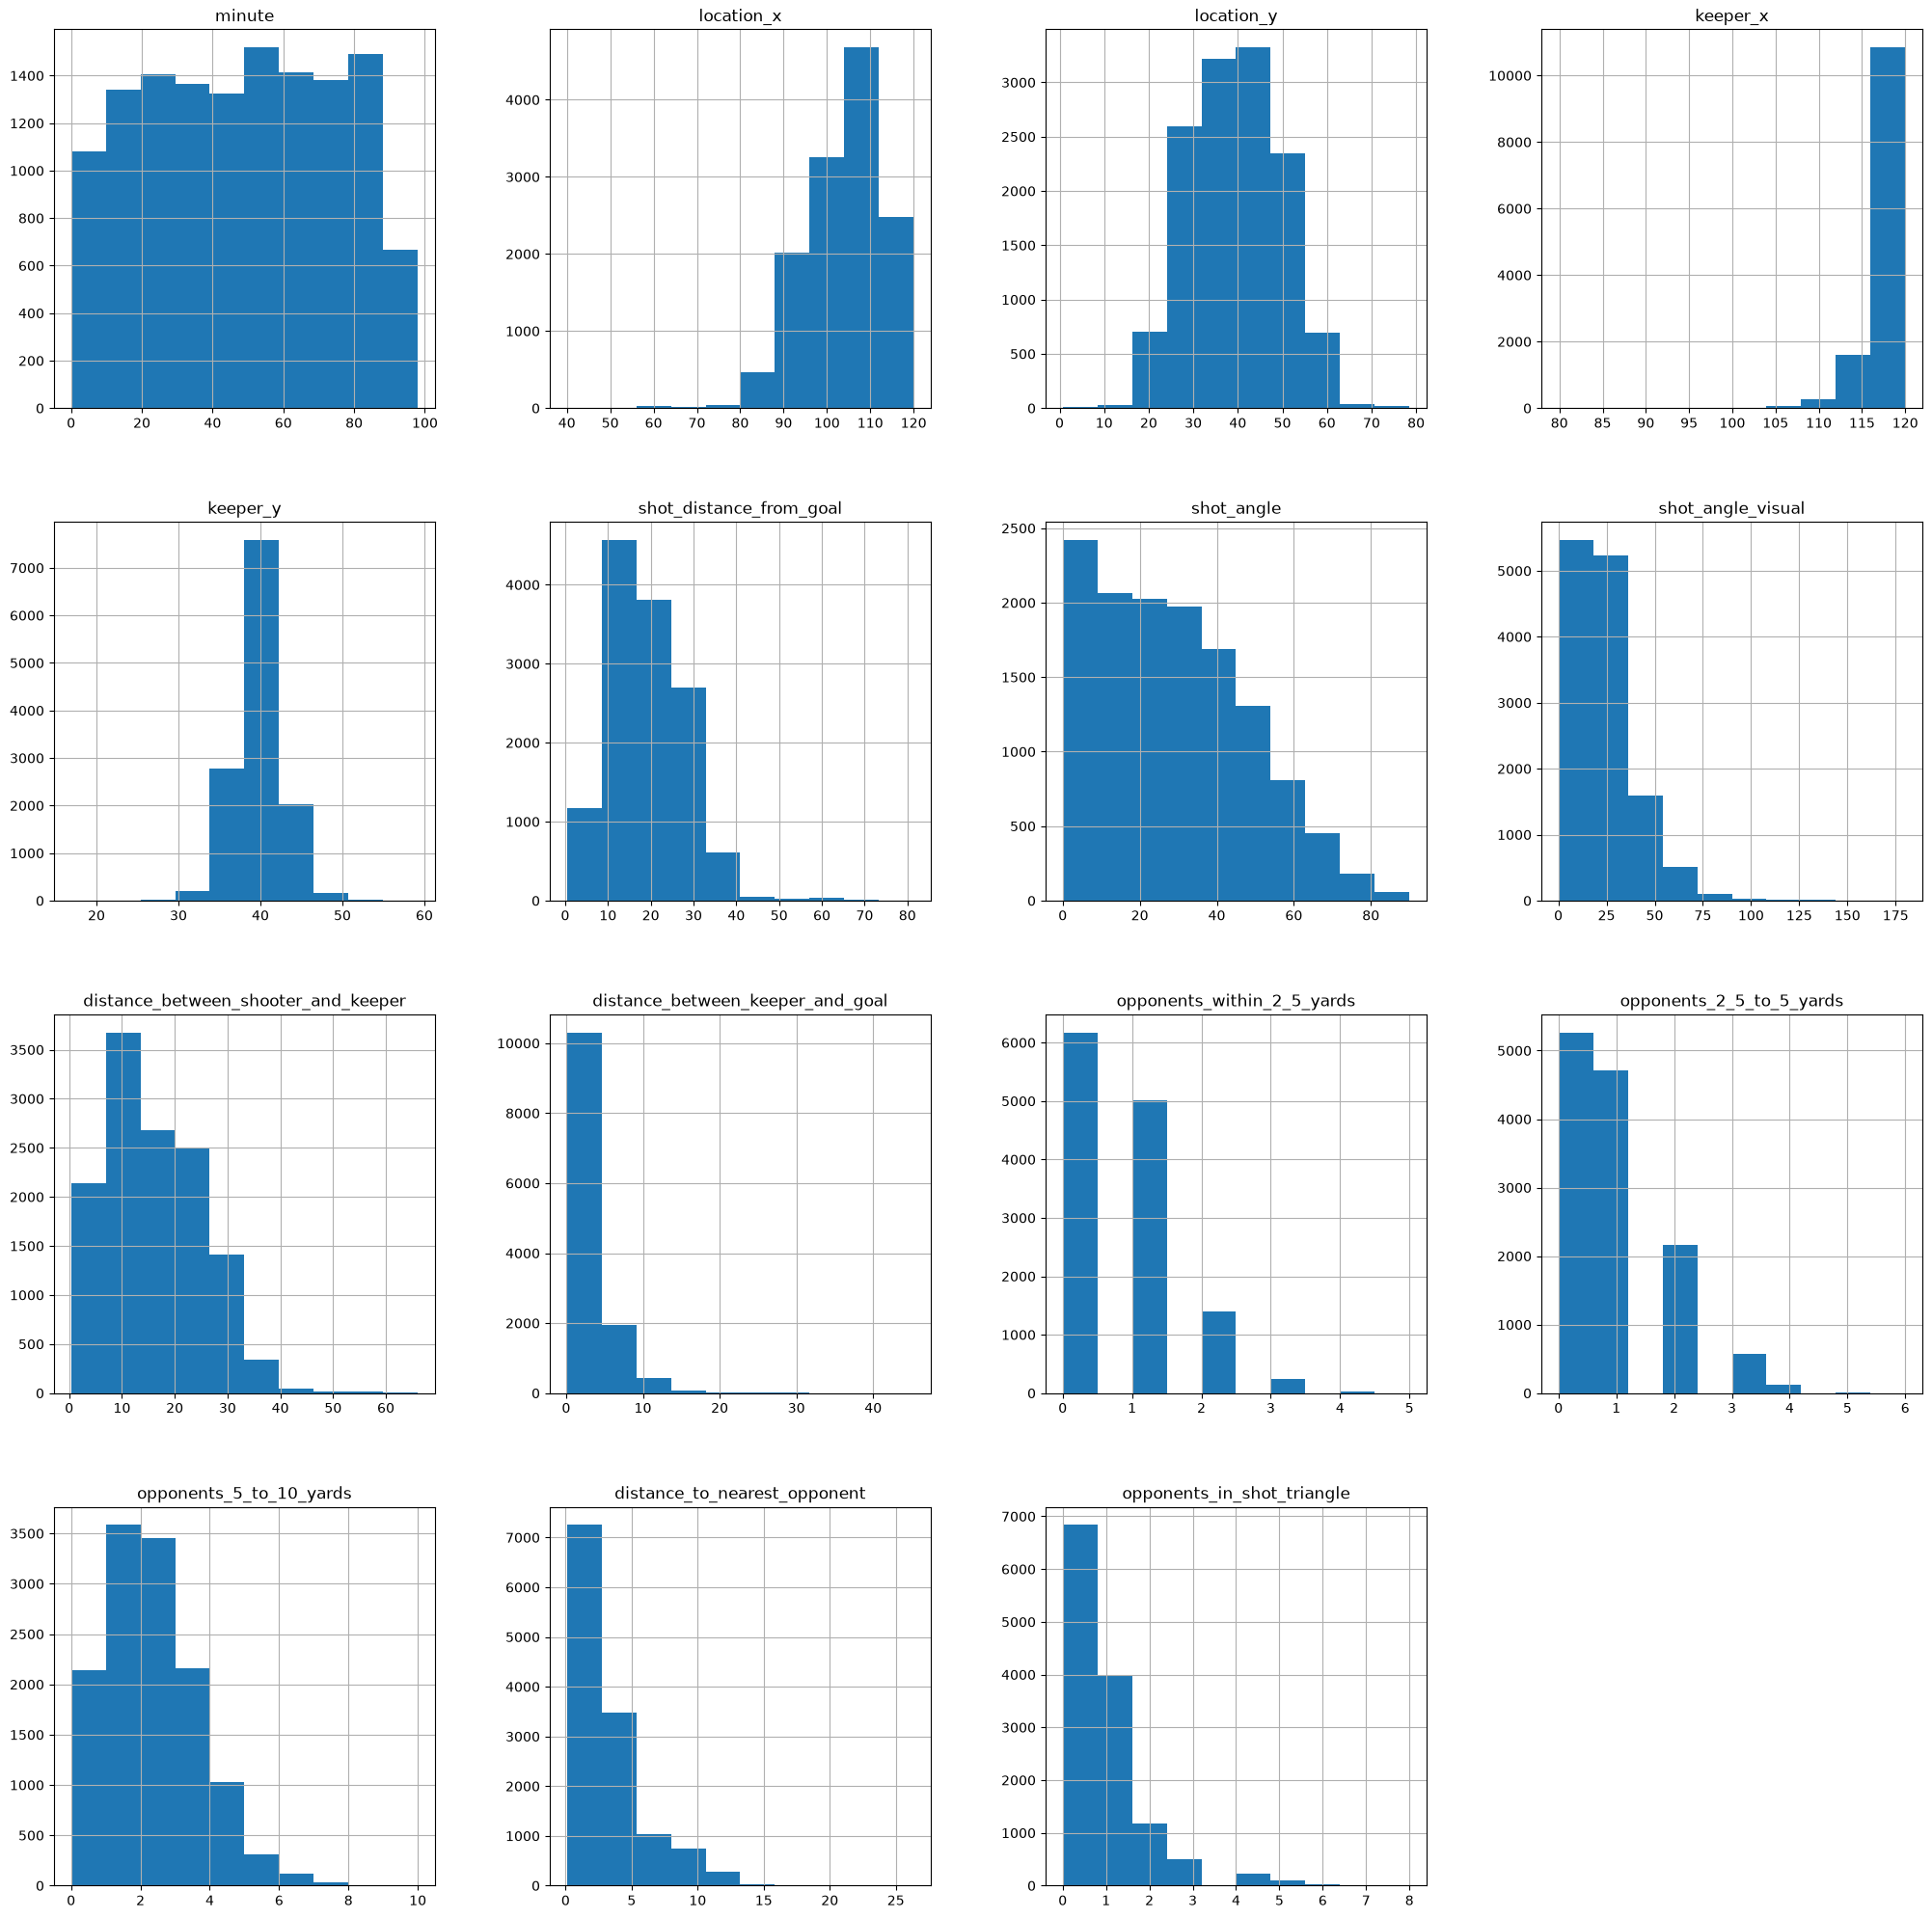

In [58]:
fig, ax = plt.subplots(1, 1 ,figsize=(25,25))
barcelona_shots[numeric_features].hist(ax=ax)

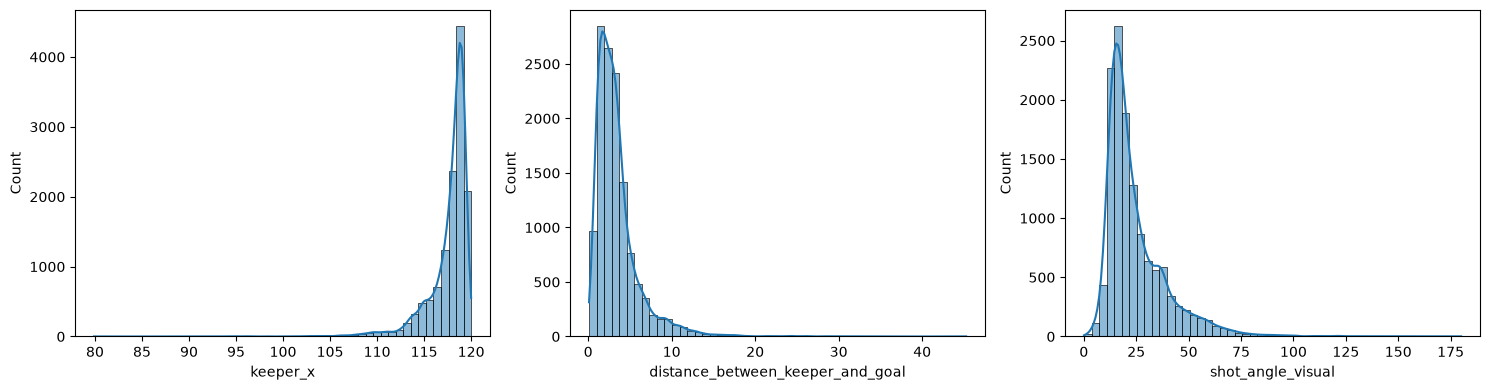

In [78]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

sbn.histplot(barcelona_shots["keeper_x"], bins=50, kde=True, ax=ax[0])
ax[0].set_xlabel("keeper_x")

sbn.histplot(barcelona_shots["distance_between_keeper_and_goal"], bins=50, kde=True, ax=ax[1])
ax[1].set_xlabel("distance_between_keeper_and_goal")

sbn.histplot(barcelona_shots["shot_angle_visual"], bins=50, kde=True, ax=ax[2])
ax[2].set_xlabel("shot_angle_visual")

plt.tight_layout()
plt.show()

### Histogrammer for `keeper_x`, `distance_between_keeper_and_goal` og `shot_angle_visual`

Histogrammene bekrefter det `skew()` viste:

- **`keeper_x`:** De fleste keepere står mellom 115 og 120, med toppen rundt 118–119. Fordelingen stuper ved 120, siden keeperen ikke kan stå bak mållinjen, og har en tynn hale mot venstre ned mot 80. Venstreskjevheten kommer altså av at verdiene presses mot en fysisk grense.
- **`distance_between_keeper_and_goal`:** Toppen ligger rundt 2 yards, og fordelingen faller raskt etter det. Halen går mot 45 yards, men er nesten usynlig over ca. 15. Featuren er i praksis `keeper_x` speilvendt.
- **`shot_angle_visual`:** Toppen ligger rundt 15–20 grader, med en lang hale mot høyre opp mot 180 grader.

I alle tre er halene så lave at de er vanskelige å se. Neste steg er å undersøke hvor mange rader som faktisk ligger der. Jeg velger terskler ut fra plottene og teller radene utenfor dem.

In [81]:
(barcelona_shots["distance_between_keeper_and_goal"] > 10).sum()

np.int64(412)

In [82]:
(barcelona_shots["keeper_x"] < 105).sum()

np.int64(48)

In [83]:
(barcelona_shots["shot_angle_visual"] > 90).sum()

np.int64(72)

**Hvor mange rader ligger i halene?** Jeg valgte terskler med øyemål fra plottene og telte radene utenfor dem:

| Feature | Terskel | Antall | Andel |
|---|---|---|---|
| `distance_between_keeper_and_goal` | over 10 yards | 412 | 3,2 % |
| `keeper_x` | under 105 | 48 | 0,4 % |
| `shot_angle_visual` | over 90 grader | 72 | 0,6 % |

Det er svært få rader som gir så høy skjevhet. Bare 48 av 12 834 rader trekker `keeper_x` ned til −3,5. Disse skuddene er ekte hendelser, for eksempel en keeper som står langt ute, så de skal ikke fjernes uten grunn. Om featurene bør transformeres, avgjør jeg ved å teste en pipeline med og uten `PowerTransformer`.

<Axes: xlabel='shot_distance_from_goal', ylabel='Count'>

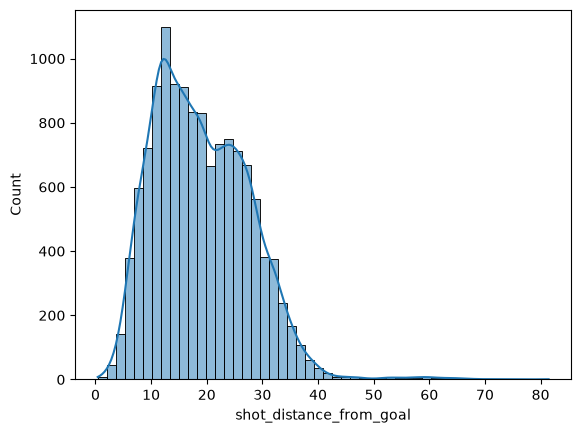

In [88]:
sbn.histplot(barcelona_shots["shot_distance_from_goal"], bins=50, kde=True)

In [92]:
barcelona_shots["shot_type"].value_counts()

shot_type
Open Play    11836
Free Kick      980
Penalty        168
Corner           1
Name: count, dtype: int64

### `shot_distance_from_goal`

Histogrammet viser at fordelingen ikke bare er skjev (0,83) med en hale mot 80 yards, men har **to topper**:

- **Rundt 12 yards.** Det er avstanden til straffemerket. Alle 168 straffer i datasettet ligger mellom 11,6 og 12,9 yards, og de samles i én søyle.
- **Rundt 22–26 yards.** Det er skudd utenfor sekstenmeteren, og her bidrar frisparkene (980 skudd, median 28,5 yards).

Formen er altså delvis en blanding av ulike skuddtyper: straffer, frispark og åpent spill. Skjevhetstallet alene viste ikke dette. Åpent spill alene har én bred topp rundt 10–14 yards med en skulder rundt 20–26 yards.

Dette er et godt argument for å beholde `shot_type` som feature, og det gir en idé til senere i EDA: et histogram delt på `shot_type` for å se at skuddtypene har ulike fordelinger.

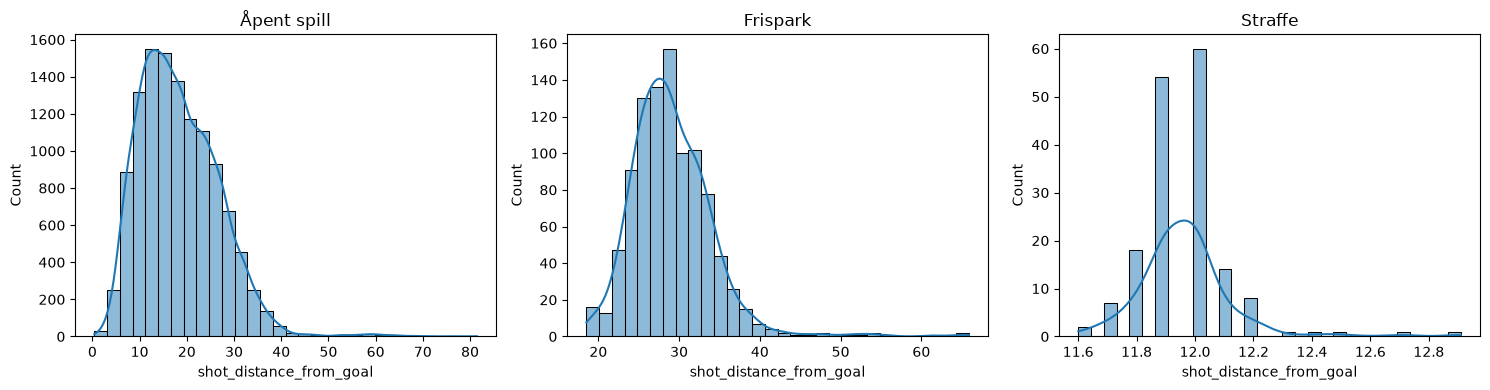

In [93]:
open_play = barcelona_shots[barcelona_shots["shot_type"] == "Open Play"]["shot_distance_from_goal"]
free_kick = barcelona_shots[barcelona_shots["shot_type"] == "Free Kick"]["shot_distance_from_goal"]
penalty = barcelona_shots[barcelona_shots["shot_type"] == "Penalty"]["shot_distance_from_goal"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

sbn.histplot(open_play, bins=30, kde=True, ax=ax[0])
ax[0].set_title("Åpent spill")
ax[0].set_xlabel("shot_distance_from_goal")

sbn.histplot(free_kick, bins=30, kde=True, ax=ax[1])
ax[1].set_title("Frispark")
ax[1].set_xlabel("shot_distance_from_goal")

sbn.histplot(penalty, bins=30, kde=True, ax=ax[2])
ax[2].set_title("Straffe")
ax[2].set_xlabel("shot_distance_from_goal")

plt.tight_layout()
plt.show()

### `shot_distance_from_goal` delt på skuddtype

Når avstanden deles etter skuddtype, blir de tre formene tydelige:

- **Åpent spill:** Én bred topp, og de fleste skuddene tas mellom ca. 12 og 20–22 yards fra mål, med en hale ut mot 80 yards.
- **Frispark:** Ligger høyere opp, med toppen rundt 28 yards. Frisparkene er med på å lage den andre toppen vi så i det samlede histogrammet.
- **Straffe:** Svært smal fordeling rundt 12 yards, siden alle straffer tas fra nesten samme punkt, med små forskjeller +-0.3

Det forklarer tvetoppen i det samlede histogrammet: den er en blanding av skuddtyper med ulike avstander.

**Neste idé:** Ta samme histogrammer, men del hver skuddtype videre etter om skuddet ble mål eller ikke. Da kan vi se om avstanden skiller mål fra ikke-mål innenfor hver skuddtype, for eksempel om målene i åpent spill kommer fra kortere avstand enn de andre skuddene.

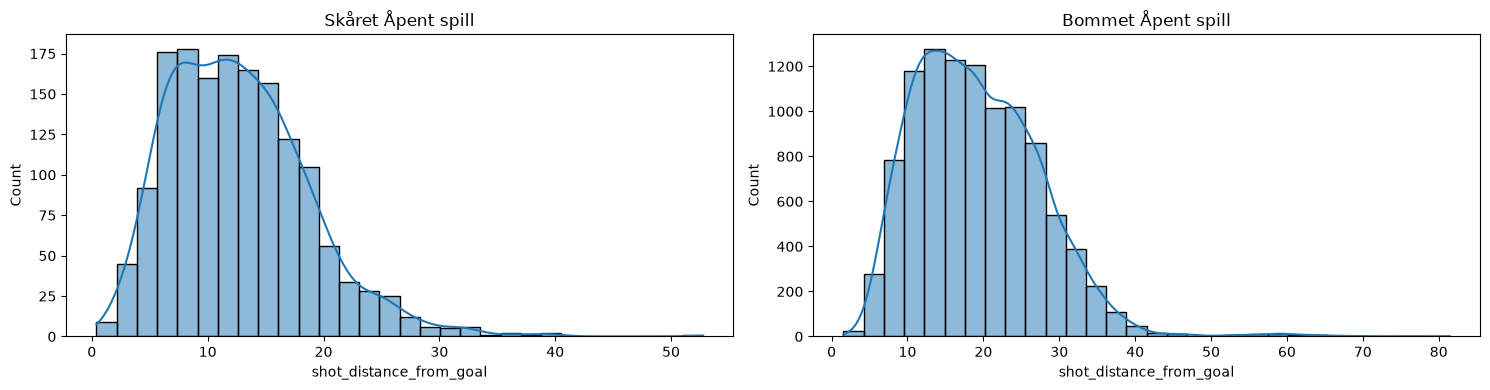

In [103]:
open_play_goal = barcelona_shots[(barcelona_shots["shot_type"] == "Open Play") & (barcelona_shots["shot_outcome_target"] == 1)]["shot_distance_from_goal"]
free_kick_goal = barcelona_shots[(barcelona_shots["shot_type"] == "Free Kick") & (barcelona_shots["shot_outcome_target"] == 1 )]["shot_distance_from_goal"]
penalty_goal = barcelona_shots[(barcelona_shots["shot_type"] == "Penalty") &(barcelona_shots["shot_outcome_target"] == 1)]["shot_distance_from_goal"]

open_play_not_goal = barcelona_shots[(barcelona_shots["shot_type"] == "Open Play") & (barcelona_shots["shot_outcome_target"] == 0)]["shot_distance_from_goal"]
free_kick_not_goal = barcelona_shots[(barcelona_shots["shot_type"] == "Free Kick") & (barcelona_shots["shot_outcome_target"] == 0 )]["shot_distance_from_goal"]
penalty_not_goal = barcelona_shots[(barcelona_shots["shot_type"] == "Penalty") &(barcelona_shots["shot_outcome_target"] == 0)]["shot_distance_from_goal"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))

sbn.histplot(open_play_goal, bins=30, kde=True, ax=ax[0])
ax[0].set_title("Skåret Åpent spill")
ax[0].set_xlabel("shot_distance_from_goal")

sbn.histplot(open_play_not_goal, bins=30, kde=True, ax=ax[1])
ax[1].set_title("Bommet Åpent spill")
ax[1].set_xlabel("shot_distance_from_goal")

plt.tight_layout()
plt.show()


### Åpent spill: avstand for mål og ikke-mål

De fleste målene i åpent spill kommer fra ca. 6–8 yards. Det blir litt færre rundt 10 yards, så stiger det igjen mellom 12 og 16, før det faller mot 18–20 yards. Etter ca. 20 yards er det få mål.

Skuddene som ikke ble mål har en bredere fordeling og tas oftere fra lengre avstand, og mange kommer fra 20–30 yards. Målene kommer altså fra kortere avstand enn de andre skuddene, men fordelingene overlapper mye. Y-aksene er ulike (langt flere skudd uten mål), så vi sammenligner formene, ikke høydene.

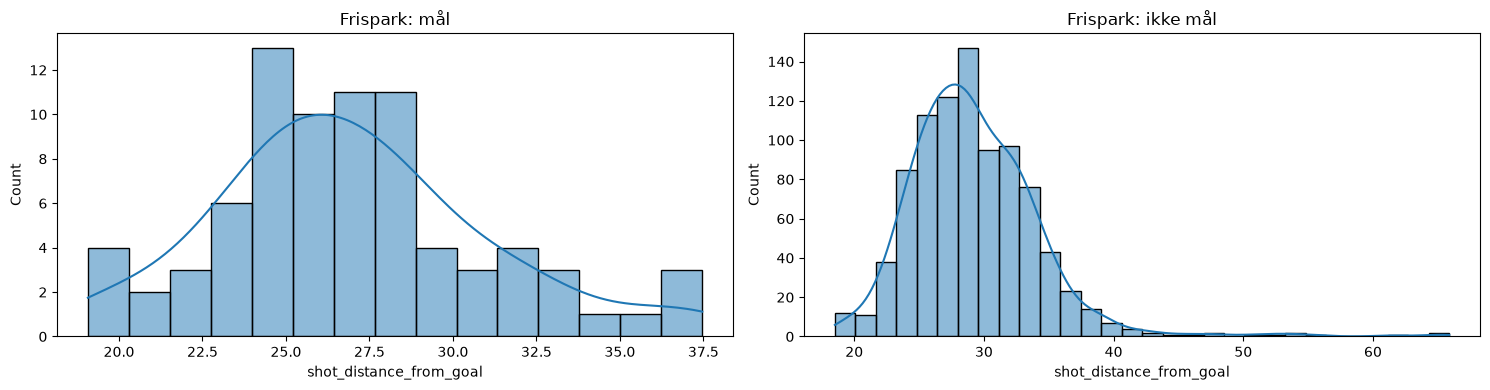

In [104]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))

sbn.histplot(free_kick_goal, bins=15, kde=True, ax=ax[0])
ax[0].set_title("Frispark: mål")
ax[0].set_xlabel("shot_distance_from_goal")

sbn.histplot(free_kick_not_goal, bins=30, kde=True, ax=ax[1])
ax[1].set_title("Frispark: ikke mål")
ax[1].set_xlabel("shot_distance_from_goal")

plt.tight_layout()
plt.show()

In [ ]:
len(free_kick_goal)

79

In [ ]:
len(free_kick_not_goal)

901

In [107]:

barcelona_shots["shot_type"].value_counts()

shot_type
Open Play    11836
Free Kick      980
Penalty        168
Corner           1
Name: count, dtype: int64

In [105]:
free_kick_not_goal.skew()

np.float64(1.8695995557357676)

### Frispark: avstand for mål og ikke-mål

Frisparkmålene (79 stykker) kommer fra ca. 19 til 37 yards, med flest rundt 24–29 yards. Ikke-målene har toppen rundt 27–30 yards, så de ligger litt lenger unna.

Ikke-målene er **sterkt høyreskjeve** (skjevhet 1,87): de fleste skuddene tas mellom ca. 22 og 38 yards, men noen få strekker seg ut mot 60–65 yards. Det er disse få skuddene som gir den høye skjevheten, mens selve toppen er omtrent symmetrisk. Det er den samme effekten vi så for de andre skjeve featurene.

Forskjellen mellom mål og ikke-mål er mye mindre enn i åpent spill. Begge fordelingene ligger i samme område, så avstand alene skiller dem dårlig for frispark. Det er også få mål, så histogrammet for målene er ujevnt, og vi bør ikke lese for mye ut av små svingninger. Y-aksene er ulike (79 mål mot 901 skudd), så vi sammenligner formene, ikke høydene.

Straffer tas fra samme punkt (ca. 12 yards), så avstanden varierer nesten ikke og sier lite om utfallet. Vi plotter dem derfor ikke mot mål og ikke-mål.

<Axes: xlabel='distance_to_nearest_opponent', ylabel='Count'>

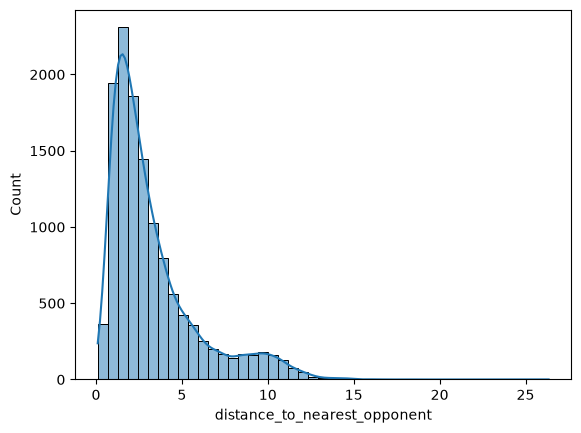

In [91]:
sbn.histplot(barcelona_shots["distance_to_nearest_opponent"], bins=45, kde=True)

### `distance_to_nearest_opponent`

Histogrammet viser at de fleste skudd tas med en motstander tett på: toppen ligger rundt 1,5–2 yards, og de fleste skuddene ligger mellom ca. 1 og 4 yards fra nærmeste motstander. Fordelingen er sterkt høyreskjev, med en hale ut mot 25 yards, men få skudd tas med mer enn 10 yards til nærmeste motstander.

Figuren viser alle skudd samlet, så den sier ikke noe om hva som skiller mål fra ikke-mål. Det ser vi på når vi deler dem opp.

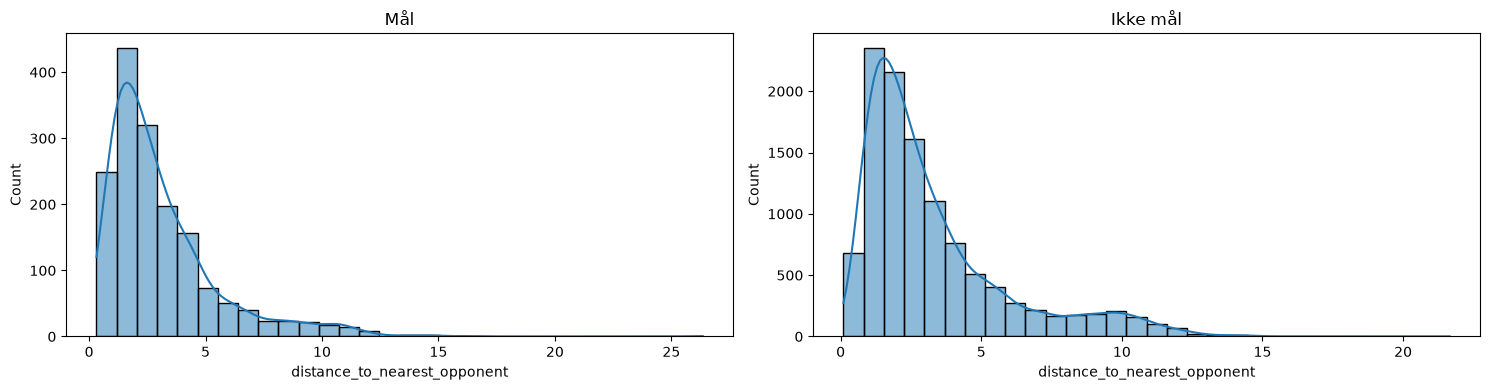

In [112]:
nearest_goal = barcelona_shots[barcelona_shots["shot_outcome_target"] == 1]["distance_to_nearest_opponent"]
nearest_not_goal = barcelona_shots[barcelona_shots["shot_outcome_target"] == 0]["distance_to_nearest_opponent"]

fig, ax = plt.subplots(1, 2, figsize=(15, 4))

sbn.histplot(nearest_goal, bins=30, kde=True, ax=ax[0])
ax[0].set_title("Mål")
ax[0].set_xlabel("distance_to_nearest_opponent")

sbn.histplot(nearest_not_goal, bins=30, kde=True, ax=ax[1])
ax[1].set_title("Ikke mål")
ax[1].set_xlabel("distance_to_nearest_opponent")

plt.tight_layout()
plt.show()

### `distance_to_nearest_opponent`: mål mot ikke-mål

De fleste målene kommer når nærmeste motstander står ca. 2 yards unna skytteren. Det betyr ikke at presset gjør det lettere å score. Ikke-målene har nesten samme form, med toppen på samme sted, så det er rett og slett der de fleste skuddene tas, uansett utfall. Y-aksene er ulike, så vi sammenligner formene, ikke høydene.

Fordi fordelingene er så like, ser featuren ut til å være svak alene: den sier ikke direkte om et skudd blir mål eller ikke. Den kan likevel tilføre noe sammen med de andre featurene, siden avstanden til nærmeste motstander også henger sammen med hvor på banen skuddet tas.

Den eneste tydelige forskjellen er at ikke-målene har en liten ekstra topp rundt 10 yards som målene nesten ikke har. Det kan ha med frispark å gjøre, men det har jeg ikke undersøkt.

In [113]:
barcelona_shots["team"].value_counts()

team
Barcelona                 8285
Real Madrid                406
Sevilla                    302
Atlético Madrid            295
Valencia                   266
Athletic Club              233
Real Sociedad              232
Villarreal                 220
Getafe                     208
Espanyol                   203
Real Betis                 194
Levante UD                 189
Celta Vigo                 174
RC Deportivo La Coruña     171
Osasuna                    139
Rayo Vallecano             136
Eibar                      132
Málaga                     119
Real Valladolid            114
Real Zaragoza              107
Mallorca                   106
Granada                     89
Leganés                     85
Racing Santander            81
Las Palmas                  67
Deportivo Alavés            66
Almería                     61
Girona                      44
Sporting Gijón              43
Recreativo Huelva           43
Cádiz                       23
Elche                       23
Rea

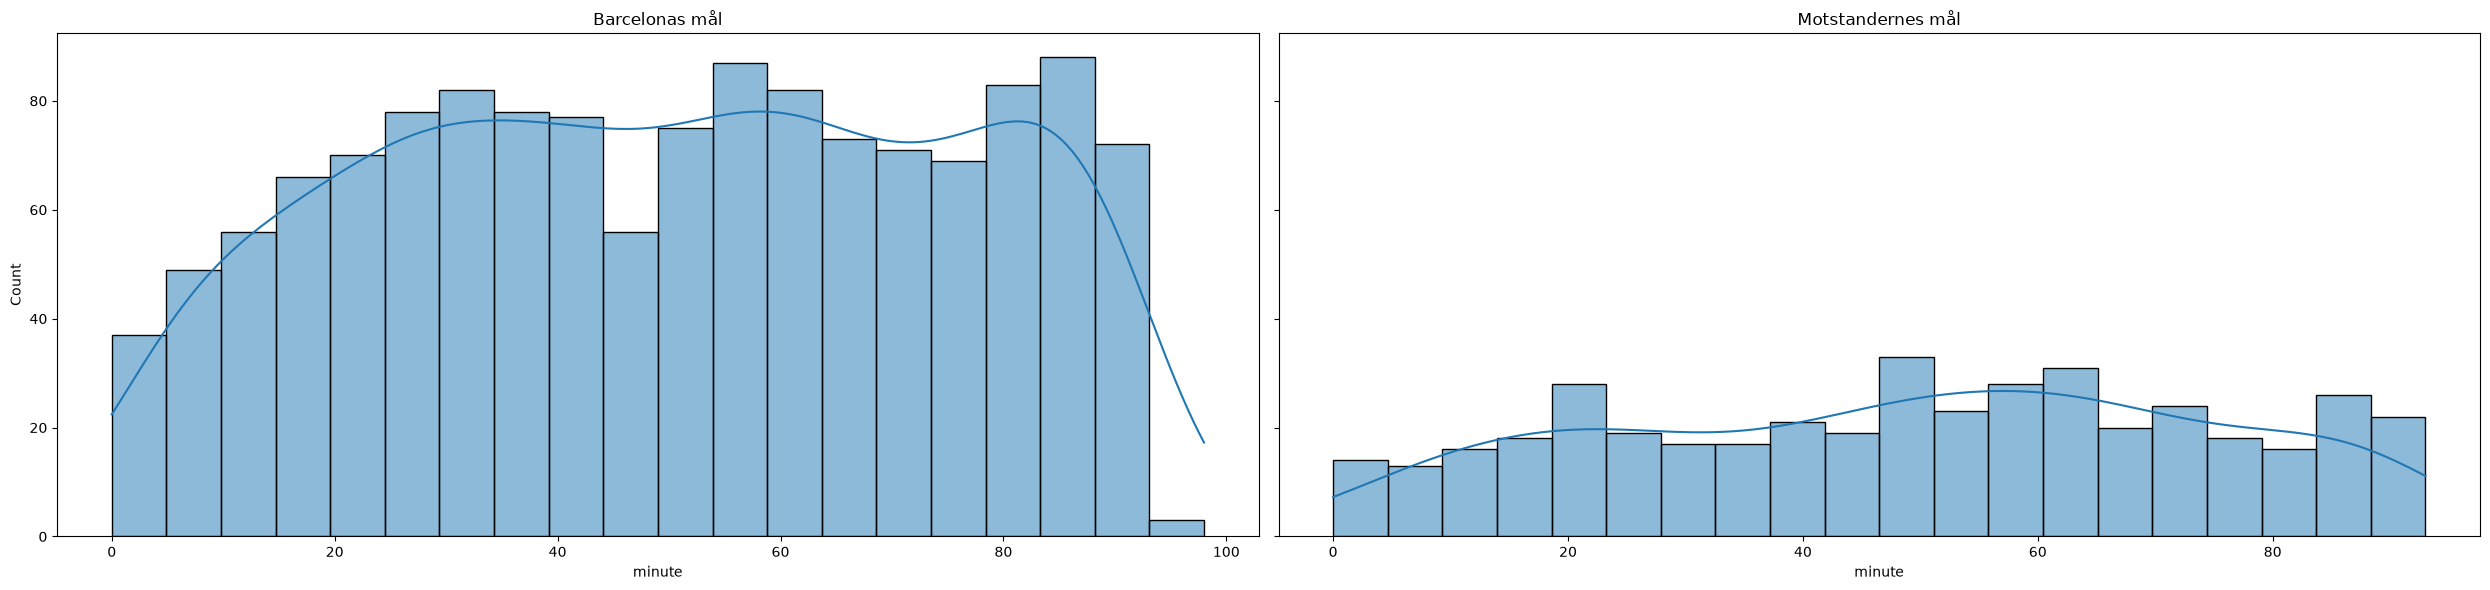

In [118]:
barca_minute = barcelona_shots[(barcelona_shots["team"] == "Barcelona") & (barcelona_shots["shot_outcome_target"]== 1)]["minute"]
others_minute = barcelona_shots[(barcelona_shots["team"] != "Barcelona") & (barcelona_shots["shot_outcome_target"]== 1)]["minute"]

fig, ax = plt.subplots(1, 2, figsize=(25, 6), sharey=True)

sbn.histplot(barca_minute, bins=20, kde=True, ax=ax[0])
ax[0].set_title("Barcelonas mål")
ax[0].set_xlabel("minute")

sbn.histplot(others_minute, bins=20, kde=True, ax=ax[1])
ax[1].set_title("Motstandernes mål")
ax[1].set_xlabel("minute")

plt.tight_layout()
plt.show()

### `minute`: når scores målene?

Figurene viser minuttene da Barcelona og motstanderne scoret. Barcelona har flest mål, og det vises tydelig siden figurene deler y-akse.

Fordelingen er ganske jevn gjennom hele kampen for "begge" lag. Det er litt færre mål de første minuttene, før det flater ut. Resten av svingningene er små og skyldes trolig tilfeldig variasjon. Den siste søylen er lav fordi det bare er noen få minutter overtid.

Dette er bare mål, så figurene viser ikke om *sjansen* for mål endrer seg gjennom kampen. For å vite det måtte vi sammenlignet med alle skuddene i samme minutter. Foreløpig ser `minute` ut til å være en svak feature, selv om jeg egentlig hadde tanke før om at når skudden blir tatt har kanskje noe å si, for skudd som kommer senere i tillegg til hvis laget ligger bra/dårlig ann så vil det påvirke om det blir mål eller ikke 

### Idé: spilleforløp (stillingen før skuddet)

Målet er å lage en modell som predikerer om et skudd blir mål, basert på det vi vet i det skuddet blir tatt: skytterens posisjon, keeperens posisjon, antall motstandere rundt skytteren, avstand til mål og keeper, to ulike vinkler mot målet og når i kampen skuddet kom.

En mulig tilleggsfeature er **stillingen før skuddet**. Med fotballkunnskap forventer jeg at det kan ha noe å si, for eksempel at lag som ligger under presser mer eller tar skudd under annen risiko enn lag som leder. Dette er en hypotese, og jeg vet ikke på forhånd hvor mye den hjelper.

Siden datasettet inneholder alle skudd i hver kamp (`match_id`), kan stillingen regnes ut ved å telle mål som kom *før* hvert skudd. Det er ikke leakage, så lenge:
- bare tidligere mål telles, aldri skuddet selv eller senere skudd
- skuddene sorteres riktig etter kamp, periode, minutt og sekund

Selvmål er ikke skudd og blir ikke telt, så stillingen kan være litt feil i noen kamper. Jeg tester featuren som en egen gruppe (`game_state_features`) i ablasjonsstudien, og sammenligner med og uten den.

Datasettet deles på kamper (`match_id`), ikke på tilfeldige skudd. Skudd fra samme kamp ligner hverandre, og ville ellers havnet både i trenings- og testdata.

### Hvorfor vi splitter på kamper, ikke på sesonger

I et tidligere prosjekt, hvor vi predikerte kampresultater, delte vi dataene på sesong. Featurene der bygde på historikk, og testdataene måtte komme etter treningsdataene for å unngå informasjon fra fremtiden.

Her er problemet et annet. Hvert skudd beskrives av situasjonen i det øyeblikket det tas (posisjon, keeper, motstandere, vinkler og tidspunkt), og ingen features bruker data fra andre kamper. Sesong har lite å si for om et skudd blir mål, og vi bruker den ikke som feature, så det er ikke et tidsserieproblem. Det som er avhengig av hverandre, er skudd fra samme kamp, som ligner hverandre og ikke må havne både i trenings- og testdata. Derfor splitter vi på kamper (`match_id`) med `StratifiedGroupKFold`, og bruker det også i nested cross-validation.

Som en mulig ekstra sjekk kunne vi trent på eldre sesonger og testet på nyere, for å se om modellen holder seg stabil over tid. Det gjør vi ikke i hovedanalysen.

In [ ]:
correlation = barcelona_shots[numeric_features].corr()

correlation.style.background_gradient(cmap='coolwarm')

,minute,second,location_x,location_y,keeper_x,keeper_y,shot_distance_from_goal,shot_angle,shot_angle_visual,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle
minute,1.000000,-0.007823,0.011442,0.014537,-0.029107,0.004343,-0.027401,-0.030344,0.012013,-0.030004,0.020838,-0.007511,-0.000346,0.005725,0.010503,0.005264
second,-0.007823,1.000000,-0.003115,0.005800,-0.002839,0.007421,0.000863,-0.000644,-0.001110,-0.000516,0.001042,-0.001928,-0.000542,0.030385,-0.002170,0.000314
location_x,0.011442,-0.003115,1.000000,-0.026784,0.039040,-0.021745,-0.936985,0.484626,0.552238,-0.918633,0.150607,0.314306,0.131719,-0.000137,-0.418783,-0.337751
location_y,0.014537,0.005800,-0.026784,1.000000,-0.025142,0.679842,0.010150,-0.046551,0.019795,0.005373,0.021139,-0.013242,-0.012596,0.002818,0.021792,-0.000676
keeper_x,-0.029107,-0.002839,0.039040,-0.025142,1.000000,0.040278,-0.015129,0.058935,-0.007251,0.228686,-0.897913,0.048498,0.040096,0.135308,0.044835,0.227793
keeper_y,0.004343,0.007421,-0.021745,0.679842,0.040278,1.000000,0.017694,-0.020700,-0.004369,0.024640,-0.041624,-0.018462,-0.012266,0.021891,0.027054,0.012762
shot_distance_from_goal,-0.027401,0.000863,-0.936985,0.010150,-0.015129,0.017694,1.000000,-0.186872,-0.720522,0.955477,-0.089005,-0.349331,-0.176686,-0.076626,0.441549,0.280447
shot_angle,-0.030344,-0.000644,0.484626,-0.046551,0.058935,-0.020700,-0.186872,1.000000,-0.203233,-0.263649,0.234454,0.010827,-0.082622,-0.180715,-0.093949,-0.257829
shot_angle_visual,0.012013,-0.001110,0.552238,0.019795,-0.007251,-0.004369,-0.720522,-0.203233,1.000000,-0.630561,-0.023445,0.279307,0.164022,0.109794,-0.292362,-0.162920
distance_between_shooter_and_keeper,-0.030004,-0.000516,-0.918633,0.005373,0.228686,0.024640,0.955477,-0.263649,-0.630561,1.000000,-0.344647,-0.324549,-0.152588,-0.019748,0.448656,0.354485


In [120]:
corr_columns = numeric_features + binary_features + [target]
correlation = barcelona_shots[corr_columns].corr()

correlation.style.background_gradient(cmap="coolwarm", axis=None, vmin=-1, vmax=1).format("{:.2f}")

,minute,location_x,location_y,keeper_x,keeper_y,shot_distance_from_goal,shot_angle,shot_angle_visual,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle,under_pressure,shot_follows_dribble,shot_aerial_won,shot_first_time,shot_one_on_one,shot_open_goal,shot_outcome_target
minute,1.00,0.01,0.01,-0.03,0.00,-0.03,-0.03,0.01,-0.03,0.02,-0.01,-0.00,0.01,0.01,0.01,-0.03,0.01,-0.01,-0.03,0.01,-0.00,0.02
location_x,0.01,1.00,-0.03,0.04,-0.02,-0.94,0.48,0.55,-0.92,0.15,0.31,0.13,-0.00,-0.42,-0.34,0.15,-0.03,0.21,0.15,0.24,0.16,0.22
location_y,0.01,-0.03,1.00,-0.03,0.68,0.01,-0.05,0.02,0.01,0.02,-0.01,-0.01,0.00,0.02,-0.00,-0.02,0.00,0.01,0.03,-0.01,0.01,0.01
keeper_x,-0.03,0.04,-0.03,1.00,0.04,-0.02,0.06,-0.01,0.23,-0.90,0.05,0.04,0.14,0.04,0.23,0.04,0.02,0.13,-0.05,-0.18,-0.09,-0.19
keeper_y,0.00,-0.02,0.68,0.04,1.00,0.02,-0.02,-0.00,0.02,-0.04,-0.02,-0.01,0.02,0.03,0.01,-0.00,-0.00,0.01,0.01,-0.02,-0.01,-0.00
shot_distance_from_goal,-0.03,-0.94,0.01,-0.02,0.02,1.00,-0.19,-0.72,0.96,-0.09,-0.35,-0.18,-0.08,0.44,0.28,-0.16,0.02,-0.26,-0.17,-0.20,-0.18,-0.27
shot_angle,-0.03,0.48,-0.05,0.06,-0.02,-0.19,1.00,-0.20,-0.26,0.23,0.01,-0.08,-0.18,-0.09,-0.26,0.01,-0.02,-0.06,0.02,0.20,0.07,-0.05
shot_angle_visual,0.01,0.55,0.02,-0.01,-0.00,-0.72,-0.20,1.00,-0.63,-0.02,0.28,0.16,0.11,-0.29,-0.16,0.13,-0.01,0.28,0.15,0.05,0.39,0.32
distance_between_shooter_and_keeper,-0.03,-0.92,0.01,0.23,0.02,0.96,-0.26,-0.63,1.00,-0.34,-0.32,-0.15,-0.02,0.45,0.35,-0.15,0.03,-0.21,-0.18,-0.26,-0.13,-0.27
distance_between_keeper_and_goal,0.02,0.15,0.02,-0.90,-0.04,-0.09,0.23,-0.02,-0.34,1.00,-0.04,-0.07,-0.18,-0.07,-0.28,-0.04,-0.02,-0.15,0.09,0.25,0.10,0.19


In [122]:
correlation = barcelona_shots[numeric_features + binary_features].corr().abs()
pairs = correlation.unstack().sort_values(ascending=False)
pairs[(pairs > 0.5) & (pairs < 1)]

shot_distance_from_goal              distance_between_shooter_and_keeper    0.955477
distance_between_shooter_and_keeper  shot_distance_from_goal                0.955477
shot_distance_from_goal              location_x                             0.936985
location_x                           shot_distance_from_goal                0.936985
                                     distance_between_shooter_and_keeper    0.918633
distance_between_shooter_and_keeper  location_x                             0.918633
distance_between_keeper_and_goal     keeper_x                               0.897913
keeper_x                             distance_between_keeper_and_goal       0.897913
shot_angle_visual                    shot_distance_from_goal                0.720522
shot_distance_from_goal              shot_angle_visual                      0.720522
location_y                           keeper_y                               0.679842
keeper_y                             location_y                  

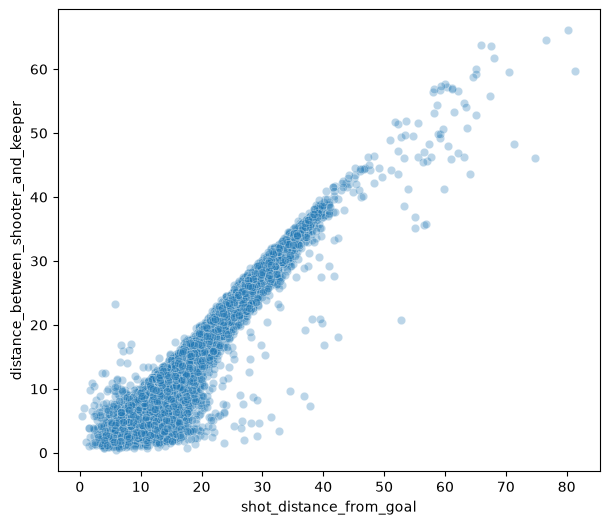

In [140]:
plt.figure(figsize=(7, 6))
sbn.scatterplot(data=barcelona_shots, x="shot_distance_from_goal", y="distance_between_shooter_and_keeper", alpha=0.3)
plt.show()

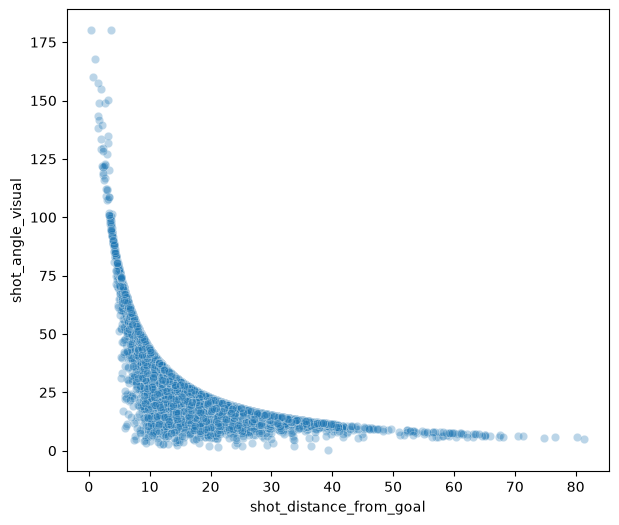

In [141]:
plt.figure(figsize=(7, 6))
sbn.scatterplot(data=barcelona_shots, x="shot_distance_from_goal", y="shot_angle_visual", alpha=0.3)
plt.show()

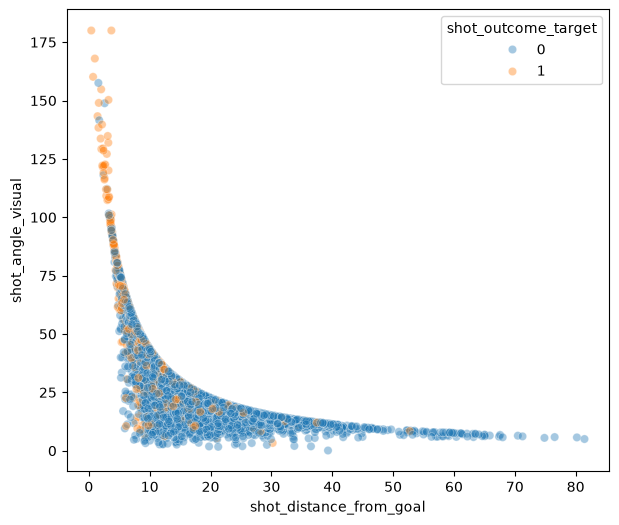

In [142]:
plt.figure(figsize=(7, 6))
sbn.scatterplot(data=barcelona_shots, x="shot_distance_from_goal", y="shot_angle_visual", hue=target, alpha=0.4)
plt.show()

#### Vinkel mot avstand

Plottet av `shot_distance_from_goal` mot `shot_angle_visual` viser en kurve, ikke en rett linje: vinkelen faller raskt de første yardene fra mål og flater ut etter ca. 20–30 yards. Kurven danner også en øvre grense, fordi vinkelen for en gitt avstand er størst når skuddet tas rett foran mål, og mindre fra sidene. De fleste målene ligger nær mål med stor vinkel, mens nesten alle skudd lenger ut er ikke-mål.

Forholdet er ikke-lineært, så korrelasjonen på 0,72 undervurderer hvor tett de to featurene henger sammen. Dette støtter at power transformation (eller PCA) kan hjelpe de lineære modellene, mens trebaserte modeller håndterer kurven uansett. Jeg tester det i pipeline.

### Korrelasjon mellom features

Jeg har sett på hvilke features som henger sammen, ved å liste alle par med absolutt korrelasjon mellom 0,5 og 1. Her er de tydeligste gruppene:

- **Nærhet til mål:** `shot_distance_from_goal`, `location_x`, `distance_between_shooter_and_keeper` og `shot_angle_visual`. Parene i denne gruppen har korrelasjon fra 0,55 til 0,96.
- **Keeper ut fra mål:** `keeper_x` og `distance_between_keeper_and_goal` (0,90).
- **Sidelengs posisjon:** `location_y` og `keeper_y` (0,68). Keeperen følger ballen sidelengs.
- **Press:** `opponents_within_2_5_yards` og `distance_to_nearest_opponent` (0,62).
- **Binære:** `under_pressure` og `shot_aerial_won` (0,57).

Mye av dette er ikke tilfeldig. Keeperen står som oftest nær mållinjen, så avstanden skytter–keeper blir nesten lik avstanden skytter–mål. Pressfeaturene måler det samme på to ulike måter.

**Hypotese:** Features som korrelerer sterkt gir nesten den samme informasjonen. De kan slås sammen til færre komponenter med PCA uten at vi mister mye, og modellene får da mindre overlappende input.

**Konsekvens for modellene:**
- Trebaserte modeller (random forest, boosting) påvirkes lite av korrelerte features.
- Logistisk regresjon og ANN påvirkes mer, så PCA er mest relevant for dem.

Dette gjør at PCA passer godt inn i delen om avansert prosessering. Senere lager jeg pipelines **med og uten PCA** og sammenligner dem med kryssvalidering, for å se om hypotesen min stemmer. PCA brukes bare på de numeriske featurene, etter skalering og inne i pipelinen, slik at vi ikke får lekkasje fra testdata.

In [123]:
cols = numeric_features + binary_features + [target]
barcelona_shots[cols].corr()[target].drop(target).sort_values()

distance_between_shooter_and_keeper   -0.272387
shot_distance_from_goal               -0.267798
keeper_x                              -0.191597
opponents_in_shot_triangle            -0.108596
shot_aerial_won                       -0.051267
shot_angle                            -0.045122
under_pressure                        -0.042041
distance_to_nearest_opponent          -0.022925
shot_follows_dribble                  -0.012597
opponents_within_2_5_yards            -0.012573
opponents_5_to_10_yards               -0.006076
keeper_y                              -0.003256
opponents_2_5_to_5_yards               0.008893
location_y                             0.014921
minute                                 0.024791
shot_one_on_one                        0.092256
shot_first_time                        0.095155
distance_between_keeper_and_goal       0.187086
location_x                             0.218472
shot_open_goal                         0.234155
shot_angle_visual                      0

### Korrelasjon mot target

Jeg sjekket korrelasjonen mellom hver feature og `shot_outcome_target`. Alle verdiene er lave. Den sterkeste er `shot_angle_visual` (0,32), etterfulgt av `distance_between_shooter_and_keeper` (−0,27) og `shot_distance_from_goal` (−0,27). Så kommer `shot_open_goal` (0,23), `location_x` (0,22), `keeper_x` (−0,19) og `distance_between_keeper_and_goal` (0,19).

Dette er ikke overraskende, av tre grunner:
- Pearson måler bare lineære sammenhenger, mens målsjansen ikke endrer seg lineært med avstand eller vinkel.
- Targeten er sjelden (13,7 % mål), og det gjør høye korrelasjoner vanskelige.
- Ingen feature har en urimelig høy korrelasjon, så det er ingen tegn til lekkasje.

Det er verdt å merke seg at `shot_angle_visual` (laget fra trekanten mot målet) korrelerer tydelig sterkere med mål enn `shot_angle` (vinkel fra midten, −0,05). Det støtter valget om å lage featuren selv. `opponents_in_shot_triangle` (−0,11) er også med blant de sterkeste, mens nærmeste motstander alene er svak (−0,02), slik vi så i histogrammene.

Lave korrelasjoner betyr ikke at featurene er ubrukelige. Modellene kan finne ikke-lineære sammenhenger og samspill mellom features, og det er der treningen skal vise verdien. Neste steg er å se på målandel per kategori og per intervall, som er mer informativt enn korrelasjon.

In [126]:
barcelona_shots.groupby("shot_body_part")[target].agg(["count", "mean"])

,count,mean
shot_body_part,,
Head,1625,0.107692
Left Foot,4919,0.147388
Other,33,0.303030
Right Foot,6408,0.134988


In [129]:
barcelona_shots.groupby("shot_technique")[target].agg(["count", "mean"])

,count,mean
shot_technique,,
Backheel,35,0.114286
Diving Header,50,0.240000
Half Volley,1275,0.113725
Lob,234,0.333333
Normal,10532,0.133973
Overhead Kick,83,0.120482
Volley,776,0.148196


In [130]:
barcelona_shots.groupby("shot_type")[target].agg(["count", "mean"])

,count,mean
shot_type,,
Corner,1,0.000000
Free Kick,980,0.080612
Open Play,11836,0.131970
Penalty,168,0.797619


In [131]:
barca_only = barcelona_shots[barcelona_shots["team"] == "Barcelona"]
barca_only.groupby("shot_type")[target].agg(["count", "mean"])

,count,mean
shot_type,,
Corner,1,0.000000
Free Kick,735,0.088435
Open Play,7433,0.160770
Penalty,116,0.793103


In [132]:
barcelona_shots.groupby("position")[target].agg(["count", "mean"])

,count,mean
position,,
Center Attacking Midfield,509,0.133595
Center Back,41,0.121951
Center Defensive Midfield,274,0.076642
Center Forward,2631,0.191562
Center Midfield,1,0.000000
Goalkeeper,1,0.000000
Left Attacking Midfield,20,0.150000
Left Back,378,0.058201
Left Center Back,328,0.106707


### Kategoriske features

Jeg har sett på antall skudd og målandel per kategori for `shot_body_part`, `shot_technique`, `shot_type` og `position`. Totalt er målandelen 13,7 %.

- **`shot_body_part`:** de fleste skuddene er med høyre fot (6408) eller venstre fot (4919), med lik målandel (13,5 % og 14,7 %). Hodestøt har lavere målandel (10,8 %).
- **`shot_technique`:** nesten alle skudd er "Normal" (10 532, 13,4 %). "Lob" skiller seg ut med 33,3 % mål på 234 skudd.
- **`shot_type`:** straffer scorer nesten alltid (79,8 %), frispark sjelden (8,1 %), og åpent spill ligger på 13,2 %. Mønsteret er det samme når jeg ser på Barcelona alene.
- **`position`:** angrepsspillere har høyest målandel (Center Forward 19,2 %), mens backer og defensive midtbanespillere ligger lavest (rundt 6–8 %).

Alle fire featurene har noen få store kategorier og flere veldig små (for eksempel "Other" med 33 skudd, "Goalkeeper" med 1 og "Corner" med 1). Målandelen i de små kategoriene er for usikker til å tolke, og de kan gi støy i modellene.

Siden kategoriene ikke har noen naturlig rekkefølge, sammenligner jeg One-Hot-Encoding og Label-/Ordinal-Encoding i pipeline. One-Hot gir flere kolonner (spesielt for `position`, med 24 verdier), mens Label-Encoding gir én kolonne, men tallene kan se ut som en rangering. Jeg tester begge med kryssvalidering, senere

In [133]:
barcelona_shots.groupby("under_pressure")[target].agg(["count", "mean"])

,count,mean
under_pressure,,
0,10877,0.143054
1,2108,0.103890


In [134]:
barcelona_shots.groupby("shot_follows_dribble")[target].agg(["count", "mean"])

,count,mean
shot_follows_dribble,,
0,12972,0.136833
1,13,0.000000


In [135]:
barcelona_shots.groupby("shot_first_time")[target].agg(["count", "mean"])

,count,mean
shot_first_time,,
0,8990,0.114905
1,3995,0.185732


In [136]:
barcelona_shots.groupby("shot_aerial_won")[target].agg(["count", "mean"])

,count,mean
shot_aerial_won,,
0,12227,0.141081
1,758,0.065963


In [137]:
barcelona_shots.groupby("shot_one_on_one")[target].agg(["count", "mean"])

,count,mean
shot_one_on_one,,
0,12051,0.127873
1,934,0.250535


In [138]:
barcelona_shots.groupby("shot_open_goal")[target].agg(["count", "mean"])

,count,mean
shot_open_goal,,
0,12817,0.127487
1,168,0.839286


### Binære features

For hver binær feature har jeg sett på antall skudd og målandel når featuren er 0 og 1.

- `shot_open_goal` er sterkest: 83,9 % av de 168 skuddene med åpent mål ble mål, mot 12,7 % ellers.
- `shot_one_on_one` gir 25,1 % mål (934 skudd) mot 12,8 %, og `shot_first_time` gir 18,6 % mål (3995 skudd) mot 11,5 %.
- `shot_aerial_won` (6,6 %, 758 skudd) og `under_pressure` (10,4 %, 2108 skudd) gir lavere målandel enn når featuren er 0 (14,1 % og 14,3 %).
- `shot_follows_dribble` har bare 13 skudd, ingen av dem mål, så den gir nesten ingen informasjon.

Flere av disse har klart ulik målandel mellom 0 og 1, selv om korrelasjonen mot targeten var lav. Det støtter at de kan hjelpe modellene, spesielt i kombinasjon med andre features. De sjeldne binære featurene (som `shot_open_goal` og `shot_follows_dribble`) har få 1-ere, så resultatene deres er mer usikre.

In [139]:
pd.crosstab(barcelona_shots["shot_type"], barcelona_shots["shot_open_goal"])

shot_open_goal,0,1
shot_type,,
Corner,1,0
Free Kick,980,0
Open Play,11668,168
Penalty,168,0


`shot_open_goal` forekommer bare i åpent spill (168 skudd), aldri ved straffer eller frispark. Den er derfor ikke det samme som `shot_type`, og gir ny informasjon.